# AMSR-CNN: Adaptive Multi-Scale, Robust, Explainable and Reliable CNN for 4-Class Brain Tumor MRI Classification

**Platform:** Kaggle (GPU T4/P100 recommended) &nbsp;|&nbsp; **Framework:** PyTorch &nbsp;|&nbsp; **Backbone:** DenseNet121 (ImageNet transfer learning)

**Primary dataset:** BRISC2025 (T1-weighted MRI; glioma / meningioma / pituitary / no tumor; 5,000 train / 1,000 test)
**External dataset:** any independent 4-class brain-tumor MRI dataset attached to the notebook (auto-detected; e.g. *Brain Tumor MRI Dataset*, Nickparvar)

### Workflow implemented (one section per block of the framework)
| § | Block | § | Block |
|---|---|---|---|
| 1 | Setup, data, leakage audit | 8 | Explainability (Grad-CAM++, IG, Occlusion) |
| 2 | Data quality assessment | 9 | Reliability (confidence, entropy, calibration, uncertainty) |
| 3 | AMEM: adaptive MRI enhancement | 10 | Robustness evaluation |
| 4 | Brain ROI extraction | 11 | External validation |
| 5 | AMSR-CNN architecture | 12 | Statistical validation (CI, tests, ablation, error analysis) |
| 6 | Training (ablation ladder x seeds) | 13 | Final model summary and export |
| 7 | Main results on BRISC2025 test | | |

**Reproducibility.** All random seeds are fixed, all splits are stratified and stored, every figure is saved at **360 DPI** (PNG + vector PDF), and every table is exported as CSV and LaTeX under `OUT_DIR`. Trained checkpoints and logits are cached so an interrupted Kaggle session resumes instead of restarting.

**Important scientific notes (please read).**
1. BRISC2025 has no patient identifiers, so slice-level splits may share patients across train/test. A perceptual-hash audit (§1) quantifies near-duplicates but cannot remove patient-level leakage. State this as a limitation in the manuscript.
2. "Brain ROI" here is the head/brain foreground region (no skull stripping); tumor focus comes from the attention modules and is *validated* with ground-truth masks in §8.
3. Quality-metric improvements after AMEM (§3) are descriptive; diagnostic benefit is only claimed through the ablation study (§12).

In [1]:
# ----------------------------------------------------------------------------------------------
# Imports
# ----------------------------------------------------------------------------------------------
import os, sys, re, json, time, math, random, shutil, pickle, warnings, copy, itertools, platform
from pathlib import Path
from collections import OrderedDict, defaultdict

import numpy as np
import pandas as pd
import cv2
from PIL import Image
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
import seaborn as sns
from scipy import ndimage as ndi, stats
from joblib import Parallel, delayed
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision

from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_recall_fscore_support,
                             f1_score, matthews_corrcoef, cohen_kappa_score, roc_auc_score, roc_curve,
                             precision_recall_curve, average_precision_score, confusion_matrix,
                             classification_report)
from sklearn.preprocessing import label_binarize
from sklearn.manifold import TSNE
from sklearn.decomposition import PCA
from statsmodels.stats.contingency_tables import mcnemar
from statsmodels.stats.multitest import multipletests

try:
    from IPython.display import display
except Exception:
    display = print

warnings.filterwarnings("ignore")
cv2.setNumThreads(1)

In [2]:
# ----------------------------------------------------------------------------------------------
# GLOBAL CONFIGURATION  (edit here only)
# ----------------------------------------------------------------------------------------------
QUICK_RUN = os.environ.get("AMSR_QUICK", "0") == "1"      # True -> tiny debug run (few epochs, 1 seed)

CFG = dict(
    seeds            = [42, 123, 2025],     # independent training runs per variant (needed for mean+-SD, CI, tests)
    split_seed       = 42,
    val_frac         = 0.15,                # stratified (class x plane) validation split taken from BRISC train
    work_size        = 320,                 # square working resolution used by quality assessment + AMEM
    img_size         = 224,                 # network input size after ROI extraction
    epochs           = 30,
    patience         = 8,
    batch_size       = 32,
    lr_backbone      = 1e-4,
    lr_head          = 5e-4,
    weight_decay     = 1e-4,
    warmup_epochs    = 2,
    proj_dim         = 256,                 # channels of every scale after projection
    head_dropout     = 0.4,
    n_boot           = 2000,                # bootstrap resamples for 95% CIs
    ece_bins         = 15,
    mc_T             = 30,                  # Monte-Carlo dropout passes
    dup_hamming      = 4,                   # dHash Hamming distance (<=) treated as near-duplicate
    xai_n            = 120,                 # test images used for quantitative XAI evaluation
    ig_steps         = 32,
    occ_patch        = 32,
    occ_stride       = 16,
    tsne_n           = 800,
)
FIG_DPI = 360                                # every saved figure

if QUICK_RUN:
    CFG.update(seeds=[42], epochs=2, patience=2, n_boot=200, mc_T=5, xai_n=12, ig_steps=8,
               occ_stride=32, tsne_n=100, img_size=int(os.environ.get("AMSR_IMG", 112)))
    print("*** QUICK_RUN enabled: numbers are NOT meaningful, this only tests the code path ***")

CLASSES   = ["glioma", "meningioma", "pituitary", "no_tumor"]
CLS_PRETTY = {"glioma": "Glioma", "meningioma": "Meningioma", "pituitary": "Pituitary", "no_tumor": "No tumor"}
N_CLS     = len(CLASSES)
CLS2ID    = {c: i for i, c in enumerate(CLASSES)}
PLANES    = ["ax", "co", "sa"]

ON_KAGGLE = Path("/kaggle").exists()
OUT_DIR   = Path(os.environ.get("AMSR_OUT", "/kaggle/working/amsr_cnn_outputs" if ON_KAGGLE else "./amsr_cnn_outputs"))
for sub in ["figures", "tables", "checkpoints", "runs", "cache"]:
    (OUT_DIR / sub).mkdir(parents=True, exist_ok=True)

DEVICE  = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"
N_JOBS  = max(1, (os.cpu_count() or 1))

# Optional overrides: put a path here if auto-discovery fails
BRISC_ROOT_OVERRIDE    = os.environ.get("BRISC_ROOT")       # folder that contains `classification_task/`
EXTERNAL_ROOT_OVERRIDE = os.environ.get("EXTERNAL_ROOT")    # folder(s) whose sub-folders are class names
PRETRAINED_WEIGHTS     = os.environ.get("DENSENET_WEIGHTS") # optional local path to torchvision densenet121 .pth
USE_PRETRAINED         = os.environ.get("AMSR_PRETRAINED", "1") == "1"

def set_seed(seed: int):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(CFG["split_seed"])

env_info = dict(python=platform.python_version(), torch=torch.__version__, torchvision=torchvision.__version__,
                numpy=np.__version__, opencv=cv2.__version__, device=str(DEVICE),
                gpu=torch.cuda.get_device_name(0) if torch.cuda.is_available() else None)
print(json.dumps(env_info, indent=2)); print("Outputs ->", OUT_DIR.resolve())

{
  "python": "3.13.15",
  "torch": "2.11.0+cu128",
  "torchvision": "0.26.0+cu128",
  "numpy": "2.1.3",
  "opencv": "4.14.0",
  "device": "cuda",
  "gpu": "Tesla T4"
}
Outputs -> /kaggle/working/amsr_cnn_outputs


In [3]:
# ----------------------------------------------------------------------------------------------
# Publication figure style + 360-DPI export helper
# ----------------------------------------------------------------------------------------------
OKABE = ["#0072B2", "#D55E00", "#009E73", "#CC79A7", "#E69F00", "#56B4E9", "#F0E442", "#000000"]
CLS_COL = {"glioma": "#D55E00", "meningioma": "#0072B2", "pituitary": "#009E73", "no_tumor": "#7F7F7F"}
DS_COL  = {"BRISC-train": "#0072B2", "BRISC-test": "#56B4E9", "External": "#D55E00"}

def set_style():
    mpl.rcParams.update({
        "figure.dpi": 100,                 # on-screen size only; every saved file uses FIG_DPI
        "savefig.dpi": FIG_DPI, "savefig.bbox": "tight", "savefig.pad_inches": 0.03,
        "font.family": "sans-serif",
        "font.sans-serif": ["Arial", "Liberation Sans", "Helvetica", "DejaVu Sans"],
        "font.size": 8, "axes.titlesize": 9, "axes.labelsize": 8.5, "xtick.labelsize": 7.5,
        "ytick.labelsize": 7.5, "legend.fontsize": 7.5, "legend.frameon": False,
        "axes.spines.top": False, "axes.spines.right": False, "axes.linewidth": 0.8,
        "lines.linewidth": 1.4, "grid.linewidth": 0.4, "grid.alpha": 0.35,
        "pdf.fonttype": 42, "ps.fonttype": 42,
    })
set_style()

def panel(ax, letter, dx=-0.12, dy=1.06):
    ax.text(dx, dy, f"({letter})", transform=ax.transAxes, fontsize=10, fontweight="bold", va="bottom")

def save_fig(fig, name, show=True):
    """Save PNG at 360 DPI (+ vector PDF), verify the DPI stored in the PNG, then display."""
    png = OUT_DIR / "figures" / f"{name}.png"
    fig.savefig(png, dpi=FIG_DPI)
    fig.savefig(OUT_DIR / "figures" / f"{name}.pdf")
    with Image.open(png) as im:
        dpi = tuple(round(float(d)) for d in im.info.get("dpi", (0, 0)))
        w, h = im.size
    assert dpi[0] == FIG_DPI, f"DPI check failed for {name}: {dpi}"
    print(f"[fig] {name}.png  {w}x{h}px  dpi={dpi}")
    if show: plt.show()
    plt.close(fig)

def save_table(df, name, index=True, float_fmt="%.4f", caption=None):
    p = OUT_DIR / "tables" / name
    df.to_csv(f"{p}.csv", index=index, float_format=float_fmt)
    try:
        df.to_latex(f"{p}.tex", index=index, float_format=lambda v: f"{v:.4f}", caption=caption, escape=True)
    except Exception as e:
        print("latex export skipped:", e)
    return df

## 1. Data: discovery, stratified split, leakage audit
* BRISC2025 is located automatically under `/kaggle/input` (folder containing `classification_task/`).
* The **external** dataset is any *other* attached dataset whose sub-folders are (a variant of) `glioma / meningioma / pituitary / notumor`. It is **never** used for training, model selection or calibration.
* A 64-bit difference-hash (dHash) audit reports near-duplicates between BRISC train/val vs. test and between BRISC vs. the external set.

In [4]:
IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}

def norm_class(name: str):
    s = re.sub(r"[^a-z]", "", name.lower())
    if s.startswith("gli"):  return "glioma"
    if s.startswith("men"):  return "meningioma"
    if s.startswith("pit"):  return "pituitary"
    if s.startswith("notum") or s in {"no", "normal", "healthy", "nontumor", "control"}: return "no_tumor"
    return None

def find_brisc_root():
    if BRISC_ROOT_OVERRIDE: return Path(BRISC_ROOT_OVERRIDE)
    for base in [Path("/kaggle/input"), Path("."), Path("/tmp/sim")]:
        if not base.exists(): continue
        for dp, dn, _ in os.walk(base):
            if "classification_task" in dn: return Path(dp)
    raise FileNotFoundError("BRISC2025 not found: attach the dataset or set BRISC_ROOT_OVERRIDE.")

def find_class_containers(base: Path, exclude=(), max_depth=5):
    hits, ex = [], [str(Path(e).resolve()) for e in exclude]
    for dp, dn, _ in os.walk(base):
        p = Path(dp)
        if len(p.relative_to(base).parts) > max_depth or any(str(p.resolve()).startswith(e) for e in ex):
            dn[:] = []; continue
        if len({norm_class(d) for d in dn} - {None}) >= 3:
            hits.append(p); dn[:] = []
    return hits

BRISC_ROOT = find_brisc_root()
print("BRISC root:", BRISC_ROOT)

# ---------------------------------------------------------------- BRISC manifest
rows = []
for p in sorted((BRISC_ROOT / "classification_task").rglob("*")):
    if p.suffix.lower() not in IMG_EXT: continue
    parts = [x.lower() for x in p.parts]
    split = "train" if "train" in parts else ("test" if "test" in parts else None)
    cls = norm_class(p.parent.name)
    if split is None or cls is None: continue
    m = re.search(r"_(ax|co|sa)_", p.name)
    rows.append(dict(path=str(p), stem=p.stem, split=split, cls=cls, y=CLS2ID[cls],
                     plane=m.group(1) if m else "unk", dataset="BRISC"))
df_brisc = pd.DataFrame(rows)
assert len(df_brisc) > 0, "No BRISC images found"

# stratified (class x plane) train/val split of the official training partition
tr = df_brisc[df_brisc.split == "train"]
strat = tr.cls + "_" + tr.plane
tr_idx, va_idx = train_test_split(tr.index, test_size=CFG["val_frac"], stratify=strat, random_state=CFG["split_seed"])
df_brisc.loc[va_idx, "split"] = "val"
df_brisc = df_brisc.sort_values(["split", "cls", "stem"]).reset_index(drop=True)
df_brisc["ds_group"] = np.where(df_brisc.split == "test", "BRISC-test", "BRISC-train")   # train+val together for descriptive stats

# GT tumor masks (only tumor slices have masks)
mask_map = {p.stem: p for p in (BRISC_ROOT / "segmentation_task").rglob("*.png") if "masks" in [x.lower() for x in p.parts]}
df_brisc["mask_path"] = df_brisc.stem.map(lambda s: str(mask_map[s]) if s in mask_map else "")
print(df_brisc.groupby(["split", "cls"]).size().unstack(fill_value=0))
print("slices with GT mask:", (df_brisc.mask_path != "").sum())

# ---------------------------------------------------------------- External dataset
ext_containers = []
if EXTERNAL_ROOT_OVERRIDE:
    ext_containers = [Path(p) for p in EXTERNAL_ROOT_OVERRIDE.split(os.pathsep)]
else:
    for base in [Path("/kaggle/input"), Path("/tmp/sim_ext")]:
        if base.exists():
            ext_containers += find_class_containers(base, exclude=[BRISC_ROOT])
rows = []
for c in ext_containers:
    for d in sorted(x for x in c.iterdir() if x.is_dir()):
        cls = norm_class(d.name)
        if cls is None: continue
        for p in sorted(d.rglob("*")):
            if p.suffix.lower() in IMG_EXT:
                rows.append(dict(path=str(p), stem=p.stem, split="external", cls=cls, y=CLS2ID[cls],
                                 plane="unk", dataset="External", mask_path="", container=str(c)))
df_ext = pd.DataFrame(rows)
HAS_EXT = len(df_ext) > 0
if HAS_EXT:
    df_ext["ds_group"] = "External"
    df_ext["stem"] = df_ext.container.str.replace(r"[^A-Za-z0-9]", "_", regex=True).str[-20:] + "_" + df_ext.stem
    print("External containers:", [str(c) for c in ext_containers])
    print(df_ext.groupby("cls").size())
else:
    print("!! No external dataset detected. Attach one (e.g. 'Brain Tumor MRI Dataset') to run §11; downstream external cells are skipped.")

BRISC root: /kaggle/input/datasets/briscdataset/brisc2025/brisc2025
cls    glioma  meningioma  no_tumor  pituitary
split                                         
test      254         306       140        300
train     975        1130       906       1239
val       172         199       161        218
slices with GT mask: 4793
!! No external dataset detected. Attach one (e.g. 'Brain Tumor MRI Dataset') to run §11; downstream external cells are skipped.


In [5]:
# ----------------------------------------------------------------------------------------------
# Load every image once, pad to square, resize to the working resolution (uint8 grayscale)
# ----------------------------------------------------------------------------------------------
WORK = CFG["work_size"]

def to_work(img: np.ndarray, size: int = WORK, interp=cv2.INTER_AREA) -> np.ndarray:
    """Pad to a square (border-median fill) so aspect ratio is preserved, then resize."""
    h, w = img.shape[:2]
    if h != w:
        s = max(h, w)
        border = np.concatenate([img[0], img[-1], img[:, 0], img[:, -1]])
        canvas = np.full((s, s), int(np.median(border)), img.dtype)
        y0, x0 = (s - h) // 2, (s - w) // 2
        canvas[y0:y0 + h, x0:x0 + w] = img
        img = canvas
    return cv2.resize(img, (size, size), interpolation=interp)

def load_work(path: str) -> np.ndarray:
    im = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    if im is None: raise IOError(path)
    return to_work(im)

def load_many(paths):
    out = Parallel(n_jobs=N_JOBS, prefer="threads")(delayed(load_work)(p) for p in tqdm(paths, desc="load", leave=False))
    return np.stack(out).astype(np.uint8)

t0 = time.time()
W_brisc = load_many(df_brisc.path.tolist())
W_ext   = load_many(df_ext.path.tolist()) if HAS_EXT else np.zeros((0, WORK, WORK), np.uint8)
print(f"loaded BRISC {W_brisc.shape}, External {W_ext.shape} in {time.time()-t0:.0f}s")

load:   0%|          | 0/6000 [00:00<?, ?it/s]

loaded BRISC (6000, 320, 320), External (0, 320, 320) in 10s


In [6]:
# ----------------------------------------------------------------------------------------------
# Leakage audit: dHash near-duplicates (Hamming distance <= CFG['dup_hamming'])
# ----------------------------------------------------------------------------------------------
_POP = np.array([bin(i).count("1") for i in range(256)], np.uint8)

def dhash(img):
    s = cv2.resize(img, (9, 8), interpolation=cv2.INTER_AREA).astype(np.int16)
    return np.packbits((s[:, 1:] > s[:, :-1]).ravel())

def min_hamming(A, B, chunk=128):
    """For each row of A: (min Hamming distance to any row of B, argmin)."""
    dmin, arg = np.empty(len(A), np.int16), np.empty(len(A), np.int64)
    for i in range(0, len(A), chunk):
        d = _POP[A[i:i + chunk, None, :] ^ B[None, :, :]].sum(2)
        dmin[i:i + chunk], arg[i:i + chunk] = d.min(1), d.argmin(1)
    return dmin, arg

H_brisc = np.stack([dhash(x) for x in W_brisc])
H_ext   = np.stack([dhash(x) for x in W_ext]) if HAS_EXT else np.zeros((0, 8), np.uint8)
thr = CFG["dup_hamming"]

is_test  = (df_brisc.split == "test").values
d_tt, a_tt = min_hamming(H_brisc[is_test], H_brisc[~is_test])
test_idx = np.where(is_test)[0]; trv_idx = np.where(~is_test)[0]
df_brisc["dup_with_train"] = False
df_brisc.loc[test_idx[d_tt <= thr], "dup_with_train"] = True
same_cls = (df_brisc.y.values[test_idx][d_tt <= thr] == df_brisc.y.values[trv_idx[a_tt[d_tt <= thr]]]).mean() if (d_tt <= thr).any() else np.nan
audit = {"BRISC test images with near-duplicate in train/val": int((d_tt <= thr).sum()),
         "  ... of which same label (fraction)": None if np.isnan(same_cls) else round(float(same_cls), 3),
         "BRISC test images total": int(is_test.sum())}
if HAS_EXT:
    d_eb, _ = min_hamming(H_ext, H_brisc)
    df_ext["dup_with_brisc"] = d_eb <= thr
    audit["External images with near-duplicate in BRISC"] = int((d_eb <= thr).sum())
    audit["External images total"] = int(len(df_ext))
print(json.dumps(audit, indent=2))
pd.Series(audit).to_csv(OUT_DIR / "tables" / "leakage_audit.csv", header=["value"])

{
  "BRISC test images with near-duplicate in train/val": 508,
  "  ... of which same label (fraction)": 0.898,
  "BRISC test images total": 1000
}


[fig] Fig01_dataset_overview.png  2208x1655px  dpi=(360, 360)


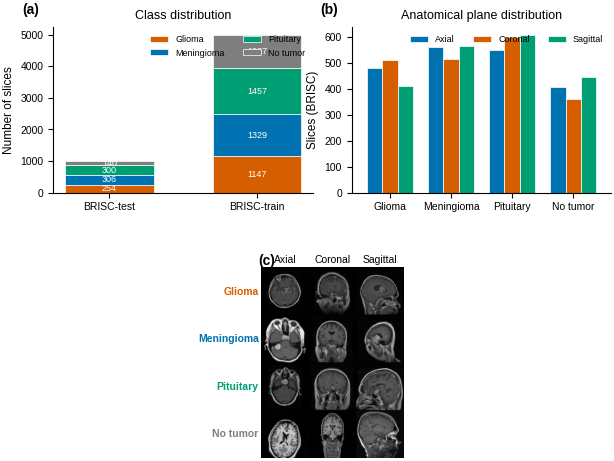

In [7]:
# ----------------------------------------------------------------------------------------------
# Figure 1: dataset overview (class / plane distributions + sample gallery)
# ----------------------------------------------------------------------------------------------
def count_table(df_all):
    return (df_all.groupby(["ds_group", "cls"]).size().unstack(fill_value=0)
            .reindex(columns=CLASSES, fill_value=0))

all_df = pd.concat([df_brisc[["ds_group", "cls", "plane", "split"]],
                    df_ext[["ds_group", "cls", "plane", "split"]] if HAS_EXT else None], ignore_index=True)
ct = count_table(all_df)
save_table(ct.assign(Total=ct.sum(1)), "T1_dataset_counts")

fig = plt.figure(figsize=(7.2, 5.6))
gs = GridSpec(2, 4, figure=fig, height_ratios=[1, 1.15], hspace=0.42, wspace=0.35)
ax = fig.add_subplot(gs[0, :2]); panel(ax, "a")
bottom = np.zeros(len(ct))
for c in CLASSES:
    ax.bar(ct.index, ct[c].values, bottom=bottom, color=CLS_COL[c], label=CLS_PRETTY[c], width=0.6, edgecolor="white", lw=0.5)
    for i, v in enumerate(ct[c].values):
        if v > 0: ax.text(i, bottom[i] + v / 2, str(v), ha="center", va="center", color="white", fontsize=6.5)
    bottom += ct[c].values
ax.set_ylabel("Number of slices"); ax.set_title("Class distribution"); ax.legend(ncol=2, fontsize=6.5, loc="upper right")
ax = fig.add_subplot(gs[0, 2:]); panel(ax, "b")
pl = all_df[all_df.ds_group != "External"].groupby(["cls", "plane"]).size().unstack(fill_value=0).reindex(index=CLASSES)
pl = pl.reindex(columns=[p for p in PLANES if p in pl.columns])
pl.plot(kind="bar", ax=ax, color=OKABE[:len(pl.columns)], width=0.75, edgecolor="white", lw=0.5)
ax.set_xticklabels([CLS_PRETTY[c] for c in CLASSES], rotation=0); ax.set_xlabel(""); ax.set_ylabel("Slices (BRISC)")
ax.set_title("Anatomical plane distribution"); ax.legend(["Axial", "Coronal", "Sagittal"][:len(pl.columns)], ncol=3, fontsize=6.5)
rng = np.random.default_rng(0)
for r, c in enumerate(CLASSES[:2] if False else CLASSES):
    pass
gal = fig.add_subplot(gs[1, :]); gal.axis("off"); panel(gal, "c", dx=-0.02, dy=1.0)
tiles = []
for c in CLASSES:
    row = []
    for p in PLANES:
        idx = np.where((df_brisc.cls == c) & (df_brisc.plane == p) & (df_brisc.split == "train"))[0]
        row.append(cv2.resize(W_brisc[rng.choice(idx)], (160, 160)) if len(idx) else np.zeros((160, 160), np.uint8))
    if HAS_EXT:
        idx = np.where(df_ext.cls == c)[0]
        row.append(cv2.resize(W_ext[rng.choice(idx)], (160, 160)) if len(idx) else np.zeros((160, 160), np.uint8))
    tiles.append(np.hstack(row))
gal.imshow(np.vstack(tiles), cmap="gray", aspect="equal")
ncol = 3 + int(HAS_EXT)
for j, t in enumerate(["Axial", "Coronal", "Sagittal", "External"][:ncol]):
    gal.text(80 + 160 * j, -8, t, ha="center", va="bottom", fontsize=7.5)
for i, c in enumerate(CLASSES):
    gal.text(-8, 80 + 160 * i, CLS_PRETTY[c], ha="right", va="center", fontsize=7.5, color=CLS_COL[c], fontweight="bold")
save_fig(fig, "Fig01_dataset_overview")

## 2. Data quality assessment (DQA)
Per-image, label-free quality descriptors are computed on the foreground (head) region of the working-resolution image:

| Descriptor | Definition | Higher means |
|---|---|---|
| **Sharpness (blur)** | variance of the Laplacian, normalised by squared mean foreground intensity | sharper |
| **Noise** | Immerkaer fast noise-sigma estimator on the foreground | noisier |
| **Contrast** | RMS contrast (std / mean) of the foreground | more contrast |
| **Artifacts** | (i) low-frequency intensity non-uniformity (bias-field proxy), (ii) saturation fraction, (iii) residual background energy (ghosting / background noise) | worse |

A composite **Quality Index (QI, 0-100)** is obtained from robust z-scores w.r.t. the BRISC *training* distribution (reference statistics never use test or external data). The same descriptors steer the quality-guided preprocessing in §3.

In [8]:
ELL = lambda k: cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k, k))
K_IMM = np.array([[1, -2, 1], [-2, 4, -2], [1, -2, 1]], np.float32)

def brain_mask(img: np.ndarray) -> np.ndarray:
    """Foreground (head/brain) mask: Otsu on a smoothed image -> closing -> largest component -> hole filling -> opening."""
    g = cv2.GaussianBlur(img, (0, 0), 2)
    t, _ = cv2.threshold(g, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    m = (g > max(8.0, 0.5 * t)).astype(np.uint8)
    m = cv2.morphologyEx(m, cv2.MORPH_CLOSE, ELL(9))
    n, lab, st, _ = cv2.connectedComponentsWithStats(m, connectivity=8)
    if n > 1:
        m = (lab == 1 + np.argmax(st[1:, cv2.CC_STAT_AREA])).astype(np.uint8)
    m = ndi.binary_fill_holes(m).astype(np.uint8)
    m = cv2.morphologyEx(m, cv2.MORPH_OPEN, ELL(5))
    if m.mean() < 0.03:                         # failed segmentation -> fall back to a permissive threshold
        m = ndi.binary_fill_holes(g > 0.1 * np.percentile(g, 99)).astype(np.uint8)
    if m.mean() < 0.03:
        m = np.ones_like(m)
    return m

def quality_metrics(img: np.ndarray, m: np.ndarray = None) -> dict:
    if m is None: m = brain_mask(img)
    f = img.astype(np.float32)
    fg = cv2.erode(m, ELL(9)) > 0
    if fg.sum() < 500: fg = m > 0
    mu = float(f[fg].mean()) + 1e-6
    lap = cv2.Laplacian(f, cv2.CV_32F, ksize=3)
    conv = cv2.filter2D(f, cv2.CV_32F, K_IMM)
    p1, p99 = np.percentile(f[fg], [1, 99])
    mf = m.astype(np.float32)
    lp = cv2.GaussianBlur(f * mf, (0, 0), 20) / (cv2.GaussianBlur(mf, (0, 0), 20) + 1e-6)
    far = cv2.dilate(m, ELL(25)) == 0
    return dict(
        sharpness      = float(lap[fg].var() / mu ** 2),
        noise          = float(np.sqrt(np.pi / 2) * np.abs(conv[fg]).mean() / 6.0),
        contrast       = float(f[fg].std() / mu),
        dyn_range      = float((p99 - p1) / 255.0),
        nonuniformity  = float(lp[fg].std() / (lp[fg].mean() + 1e-6)),
        saturation     = float((f[fg] >= 250).mean()),
        bg_residual    = float(f[far].mean() / mu) if far.sum() > 100 else 0.0,
        fg_fraction    = float(m.mean()),
    )

QCOLS = ["sharpness", "noise", "contrast", "dyn_range", "nonuniformity", "saturation", "bg_residual"]

def q_batch(imgs, masks=None):
    out = Parallel(n_jobs=N_JOBS, prefer="threads")(delayed(quality_metrics)(im) for im in tqdm(imgs, desc="DQA", leave=False))
    return pd.DataFrame(out)

t0 = time.time()
Q_brisc = q_batch(W_brisc)
Q_ext   = q_batch(W_ext) if HAS_EXT else pd.DataFrame(columns=Q_brisc.columns)
print(f"quality descriptors computed in {time.time()-t0:.0f}s")

# reference statistics (median, IQR) from BRISC *training* images only
ref_rows = (df_brisc.split != "test").values
QREF = {k: (float(Q_brisc.loc[ref_rows, k].median()),
            float(max(Q_brisc.loc[ref_rows, k].quantile(.75) - Q_brisc.loc[ref_rows, k].quantile(.25), 1e-4)))
        for k in QCOLS}

def badness(q: dict) -> dict:
    z = lambda k: (q[k] - QREF[k][0]) / QREF[k][1]
    return dict(blur_bad=-z("sharpness"), noise_bad=z("noise"), contrast_bad=-z("contrast"),
                artifact_bad=np.mean([z("nonuniformity"), z("saturation"), z("bg_residual")], axis=0))

def quality_index(Q: pd.DataFrame) -> pd.Series:
    b = pd.DataFrame(badness({k: Q[k].values for k in QCOLS}))
    return pd.Series(100.0 / (1.0 + np.exp(b.clip(-3, 3).mean(1).values)), index=Q.index, name="QI")

Q_brisc["QI"] = quality_index(Q_brisc)
if HAS_EXT: Q_ext["QI"] = quality_index(Q_ext)

DQA:   0%|          | 0/6000 [00:00<?, ?it/s]

quality descriptors computed in 51s


,BRISC-train,BRISC-test
sharpness,"0.665 [0.454, 0.868]","0.68 [0.455, 0.899]"
noise,"1.12 [0.99, 1.27]","1.13 [0.972, 1.29]"
contrast,"0.463 [0.428, 0.502]","0.466 [0.433, 0.504]"
dyn_range,"0.678 [0.627, 0.733]","0.682 [0.624, 0.745]"
nonuniformity,"0.127 [0.0944, 0.157]","0.126 [0.0936, 0.156]"
saturation,"0 [0, 0]","0 [0, 0]"
bg_residual,"0.0277 [0.0129, 0.0575]","0.0275 [0.0131, 0.0576]"
QI,"48.9 [44, 53.8]","49.1 [44.3, 53.8]"


[fig] Fig02_data_quality_assessment.png  2243x1747px  dpi=(360, 360)


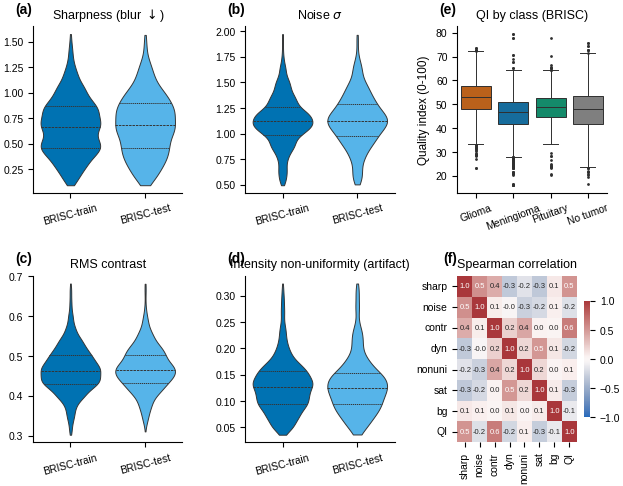

In [9]:
# ----------------------------------------------------------------------------------------------
# Table 2 + Figure 2: quality distributions across datasets / classes
# ----------------------------------------------------------------------------------------------
Q_all = pd.concat([Q_brisc.assign(ds_group=df_brisc.ds_group.values, cls=df_brisc.cls.values),
                   Q_ext.assign(ds_group="External", cls=df_ext.cls.values) if HAS_EXT else None], ignore_index=True)
groups = [g for g in ["BRISC-train", "BRISC-test", "External"] if g in set(Q_all.ds_group)]

def med_iqr(s): return f"{s.median():.3g} [{s.quantile(.25):.3g}, {s.quantile(.75):.3g}]"
t2 = pd.DataFrame({g: {k: med_iqr(Q_all.loc[Q_all.ds_group == g, k]) for k in QCOLS + ["QI"]} for g in groups})
if "External" in groups:
    pv, rb = {}, {}
    for k in QCOLS + ["QI"]:
        a, b = Q_all.loc[Q_all.ds_group == "BRISC-train", k], Q_all.loc[Q_all.ds_group == "External", k]
        U, p = stats.mannwhitneyu(a, b, alternative="two-sided")
        pv[k] = p; rb[k] = 2 * U / (len(a) * len(b)) - 1          # rank-biserial correlation
    t2["MWU p (BRISC-train vs External)"] = pd.Series(pv).map(lambda p: "<0.001" if p < 1e-3 else f"{p:.3f}")
    t2["rank-biserial r"] = pd.Series(rb).round(2)
save_table(t2, "T2_quality_descriptors", float_fmt="%.3f"); display(t2)

fig = plt.figure(figsize=(7.4, 5.4)); gs = GridSpec(2, 3, figure=fig, hspace=0.5, wspace=0.42)
titles = {"sharpness": "Sharpness (blur $\\downarrow$)", "noise": "Noise $\\sigma$", "contrast": "RMS contrast",
          "nonuniformity": "Intensity non-uniformity (artifact)"}
for i, (k, tt) in enumerate(titles.items()):
    ax = fig.add_subplot(gs[i // 2, i % 2] if i < 2 else gs[1, i - 2]); panel(ax, "abcd"[i])
    ax = ax
    lo, hi = Q_all[k].quantile([.005, .995])
    sns.violinplot(data=Q_all[Q_all[k].between(lo, hi)], x="ds_group", y=k, order=groups, palette=[DS_COL[g] for g in groups],
                   inner="quartile", linewidth=0.7, cut=0, ax=ax, saturation=1)
    ax.set_xlabel(""); ax.set_ylabel(""); ax.set_title(tt); ax.tick_params(axis="x", labelrotation=15)
ax = fig.add_subplot(gs[0, 2]); panel(ax, "e")
sns.boxplot(data=Q_all[Q_all.ds_group.str.startswith("BRISC")], x="cls", y="QI", order=CLASSES, palette=[CLS_COL[c] for c in CLASSES],
            fliersize=1, linewidth=0.7, ax=ax)
ax.set_xticklabels([CLS_PRETTY[c] for c in CLASSES], rotation=20); ax.set_xlabel(""); ax.set_ylabel("Quality index (0-100)"); ax.set_title("QI by class (BRISC)")
ax = fig.add_subplot(gs[1, 2]); panel(ax, "f")
cm_ = Q_all[QCOLS + ["QI"]].corr(method="spearman")
sns.heatmap(cm_, cmap="vlag", center=0, vmin=-1, vmax=1, annot=True, fmt=".1f", annot_kws={"size": 5.5}, cbar_kws={"shrink": .7},
            xticklabels=["sharp", "noise", "contr", "dyn", "nonuni", "sat", "bg", "QI"], yticklabels=["sharp", "noise", "contr", "dyn", "nonuni", "sat", "bg", "QI"], ax=ax)
ax.set_title("Spearman correlation")
save_fig(fig, "Fig02_data_quality_assessment")

## 3. Adaptive MRI Enhancement Module (AMEM)
AMEM is a **deterministic, quality-guided** pipeline (no learnable parameters, hence no label leakage). Every stage strength is derived from the image's own DQA descriptors relative to the BRISC-train reference:

1. **Intensity normalisation**: percentile windowing [p1, p99.5] inside the foreground mask -> [0, 255].
2. **Denoising**: non-local means with strength `h = f(noise)`; skipped if the image is already clean.
3. **Contrast enhancement**: CLAHE whose clip limit rises as the image's RMS contrast falls below the reference.
4. **Adaptive sharpening**: unsharp masking whose gain is proportional to measured blur.
5. **Background suppression**: multiplication by a feathered foreground mask (removes background noise/ghosting).

In [10]:
def amem_params(q: dict, sig_norm: float) -> dict:
    b = badness({k: np.array([q[k]]) for k in QCOLS})
    bad_blur, bad_noise, bad_con = float(b["blur_bad"][0]), float(b["noise_bad"][0]), float(b["contrast_bad"][0])
    return dict(
        h        = float(np.clip(0.9 * sig_norm + max(bad_noise, 0.0), 1.5, 14.0)) if sig_norm > 1.0 else 0.0,
        clip     = float(np.clip(2.0 + 0.6 * bad_con, 1.5, 4.0)),
        sharpen  = float(np.clip(0.35 * max(bad_blur, 0.0), 0.0, 1.0)),
    )

def amem_enhance(img: np.ndarray, q: dict, return_stages: bool = False):
    m = brain_mask(img); fg = m > 0
    f = img.astype(np.float32)
    lo, hi = np.percentile(f[fg], [1.0, 99.5])
    norm = np.clip((f - lo) / (hi - lo + 1e-6), 0, 1) * 255.0                           # (1) normalisation
    par = amem_params(q, q["noise"] * 255.0 / (hi - lo + 1e-6))
    u8 = norm.astype(np.uint8)
    den = cv2.fastNlMeansDenoising(u8, None, h=par["h"], templateWindowSize=5, searchWindowSize=15) if par["h"] > 0 else u8   # (2)
    cl = cv2.createCLAHE(clipLimit=par["clip"], tileGridSize=(8, 8)).apply(den)          # (3)
    if par["sharpen"] > 0.02:                                                            # (4)
        g = cv2.GaussianBlur(cl.astype(np.float32), (0, 0), 1.5)
        sh = np.clip(cl.astype(np.float32) + par["sharpen"] * (cl.astype(np.float32) - g), 0, 255).astype(np.uint8)
    else:
        sh = cl
    soft = cv2.GaussianBlur(cv2.dilate(m, ELL(7)).astype(np.float32), (0, 0), 3)         # (5)
    out = (sh.astype(np.float32) * soft).astype(np.uint8)
    if return_stages:
        return out, m, par, OrderedDict(original=img, normalised=u8, denoised=den, clahe=cl, sharpened=sh, final=out)
    return out, m, par

## 4. Brain ROI extraction
The ROI is the tight **square bounding box of the foreground mask** (plus a 4 % margin, clipped to the image), resized to the network resolution. This removes empty background so that the CNN sees a *brain-focused spatial representation* at a consistent scale across planes and datasets.

In [11]:
def roi_box(m: np.ndarray, margin: float = 0.04):
    ys, xs = np.where(m > 0)
    S = m.shape[0]
    y0, y1, x0, x1 = ys.min(), ys.max() + 1, xs.min(), xs.max() + 1
    side = int(min(S, max(y1 - y0, x1 - x0) + 2 * margin * S))
    cy, cx = (y0 + y1) // 2, (x0 + x1) // 2
    ty = int(np.clip(cy - side // 2, 0, S - side)); tx = int(np.clip(cx - side // 2, 0, S - side))
    return ty, ty + side, tx, tx + side

def roi_crop(img, box, out, interp=cv2.INTER_AREA):
    y0, y1, x0, x1 = box
    return cv2.resize(img[y0:y1, x0:x1], (out, out), interpolation=interp)

IMG = CFG["img_size"]

def run_pipeline_one(img: np.ndarray, q: dict = None):
    """work-res uint8 image -> (raw input, AMEM+ROI input, ROI box, post-AMEM quality, AMEM params)."""
    if q is None: q = quality_metrics(img)
    enh, m, par = amem_enhance(img, q)
    box = roi_box(m)
    return (cv2.resize(img, (IMG, IMG), interpolation=cv2.INTER_AREA), roi_crop(enh, box, IMG),
            np.array(box, np.int16), quality_metrics(enh), par)

def run_pipeline(W: np.ndarray, Q: pd.DataFrame = None, desc="AMEM+ROI"):
    qs = [None] * len(W) if Q is None else Q[QCOLS + ["fg_fraction"]].to_dict("records")
    res = Parallel(n_jobs=N_JOBS, prefer="threads")(delayed(run_pipeline_one)(w, q) for w, q in tqdm(list(zip(W, qs)), desc=desc, leave=False))
    X_raw = np.stack([r[0] for r in res]); X_am = np.stack([r[1] for r in res]); boxes = np.stack([r[2] for r in res])
    Qa = pd.DataFrame([r[3] for r in res]); Qa["QI"] = quality_index(Qa)
    pars = pd.DataFrame([r[4] for r in res])
    return X_raw, X_am, boxes, Qa, pars

t0 = time.time()
Xraw_b, Xam_b, box_b, Qa_brisc, par_brisc = run_pipeline(W_brisc, Q_brisc)
if HAS_EXT: Xraw_e, Xam_e, box_e, Qa_ext, par_ext = run_pipeline(W_ext, Q_ext)
else: Xraw_e = Xam_e = np.zeros((0, IMG, IMG), np.uint8); Qa_ext = pd.DataFrame()
print(f"AMEM + ROI done in {time.time()-t0:.0f}s | inputs {Xam_b.shape}")

# Ground-truth tumor masks mapped through the *same* pad/resize/ROI transform (test split, tumor slices)
def load_gt_mask(path, box):
    if not path: return np.zeros((IMG, IMG), bool)
    mk = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    mk = to_work((mk > 127).astype(np.uint8) * 255, interp=cv2.INTER_NEAREST)
    return roi_crop(mk, box, IMG, interp=cv2.INTER_NEAREST) > 127
test_mask_rows = np.where((df_brisc.split == "test").values)[0]
GT_test = np.stack([load_gt_mask(df_brisc.mask_path[i], box_b[i]) for i in test_mask_rows])
print("test masks:", GT_test.shape, "| tumor slices with mask:", int((GT_test.reshape(len(GT_test), -1).any(1)).sum()))

AMEM+ROI:   0%|          | 0/6000 [00:00<?, ?it/s]

AMEM + ROI done in 338s | inputs (6000, 224, 224)
test masks: (1000, 224, 224) | tumor slices with mask: 860


[fig] Fig03_AMEM_pipeline_stages.png  2298x1184px  dpi=(360, 360)


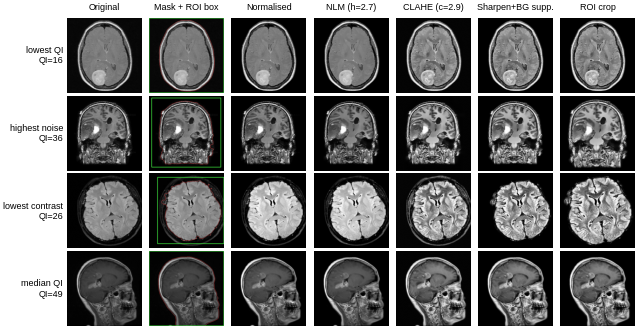

In [12]:
# ----------------------------------------------------------------------------------------------
# Figure 3: AMEM stages (worst-quality, noisiest, lowest-contrast, median-quality examples) + ROI box
# ----------------------------------------------------------------------------------------------
te = np.where((df_brisc.split == "test").values)[0]
qi_te = Q_brisc.QI.values[te]
picks = [te[np.argmin(qi_te)], te[np.argmax(Q_brisc.noise.values[te])], te[np.argmin(Q_brisc.contrast.values[te])],
         te[np.argsort(qi_te)[len(te) // 2]]]
labels = ["lowest QI", "highest noise", "lowest contrast", "median QI"]
fig, axes = plt.subplots(len(picks), 7, figsize=(7.4, 4.0))
for r, i in enumerate(picks):
    out, m, par, st = amem_enhance(W_brisc[i], Q_brisc.loc[i, QCOLS + ["fg_fraction"]].to_dict(), return_stages=True)
    box = roi_box(m)
    ov = cv2.cvtColor(W_brisc[i], cv2.COLOR_GRAY2RGB)
    cnt, _ = cv2.findContours(m, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE); cv2.drawContours(ov, cnt, -1, (255, 60, 60), 1)
    y0, y1, x0, x1 = box; cv2.rectangle(ov, (x0, y0), (x1 - 1, y1 - 1), (60, 220, 60), 2)
    ims = [st["original"], ov, st["normalised"], st["denoised"], st["clahe"], st["final"], roi_crop(st["final"], box, WORK)]
    ttl = ["Original", "Mask + ROI box", "Normalised", f"NLM (h={par['h']:.1f})", f"CLAHE (c={par['clip']:.1f})", f"Sharpen+BG supp.", "ROI crop"]
    for c, (a, t) in enumerate(zip(ims, ttl)):
        axes[r, c].imshow(a, cmap="gray" if a.ndim == 2 else None, vmin=0, vmax=255); axes[r, c].axis("off")
        if r == 0: axes[r, c].set_title(t, fontsize=6.5)
    axes[r, 0].text(-0.05, 0.5, f"{labels[r]}\nQI={Q_brisc.QI[i]:.0f}", transform=axes[r, 0].transAxes, ha="right", va="center", fontsize=6.5)
plt.subplots_adjust(wspace=0.03, hspace=0.04)
save_fig(fig, "Fig03_AMEM_pipeline_stages")

[fig] Fig04_quality_before_after_AMEM.png  2599x755px  dpi=(360, 360)


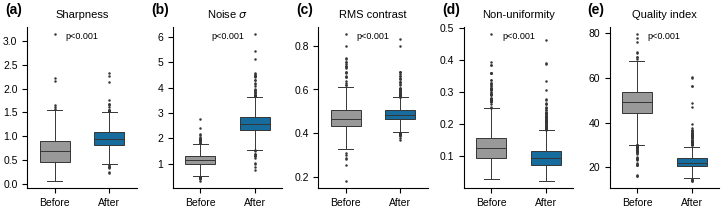

,median_before,median_after,wilcoxon_p
metric,,,
sharpness,0.679807,0.932785,3.865943e-151
noise,1.127069,2.576124,3.325844e-165
contrast,0.466118,0.482288,5.751031e-38
nonuniformity,0.125639,0.093897,2.936390e-156
QI,49.092846,22.141089,6.171746e-165


In [13]:
# ----------------------------------------------------------------------------------------------
# Figure 4: quality before vs after AMEM (BRISC test, paired Wilcoxon) + ROI examples
# ----------------------------------------------------------------------------------------------
mets = [("sharpness", "Sharpness"), ("noise", "Noise $\\sigma$"), ("contrast", "RMS contrast"), ("nonuniformity", "Non-uniformity"), ("QI", "Quality index")]
fig, axes = plt.subplots(1, 5, figsize=(7.4, 2.3)); rows_stat = []
for ax, (k, t), L in zip(axes, mets, "abcde"):
    b, a = Q_brisc[k].values[te], Qa_brisc[k].values[te]
    W_, p = stats.wilcoxon(b, a)
    rows_stat.append(dict(metric=k, median_before=np.median(b), median_after=np.median(a), wilcoxon_p=p))
    d = pd.DataFrame({"v": np.r_[b, a], "s": ["Before"] * len(b) + ["After"] * len(a)})
    sns.boxplot(data=d, x="s", y="v", palette=["#999999", "#0072B2"], fliersize=0.8, linewidth=0.7, ax=ax, width=0.55)
    ax.set_xlabel(""); ax.set_ylabel(""); ax.set_title(t, fontsize=8); panel(ax, L, dx=-0.2)
    ax.text(0.5, 0.97, "p<0.001" if p < 1e-3 else f"p={p:.3f}", transform=ax.transAxes, ha="center", va="top", fontsize=6.5)
plt.tight_layout(); save_fig(fig, "Fig04_quality_before_after_AMEM")
save_table(pd.DataFrame(rows_stat).set_index("metric"), "T3_quality_before_after_AMEM")

*Interpretation note.* AMEM is normalising intensity and background, so some descriptors shift by construction (e.g. contrast after CLAHE). These plots document what the preprocessing does; whether it helps **diagnostic performance and robustness** is tested in the ablation (§12) and perturbation study (§10), not inferred from these metrics.

## 5. AMSR-CNN architecture
```
MRI -> DenseNet121 encoder (ImageNet transfer learning)
        |-- Fine         : denseblock2 output (512 ch, 1/8 resolution)
        |-- Intermediate : denseblock3 output (1024 ch, 1/16)
        `-- Deep         : norm5 output       (1024 ch, 1/32)
 each scale:  1x1 projection -> Tumor-aware attention (channel + spatial, CBAM-style)
 AMSF      :  F = a1*F1 + a2*F2 + a3*F3,   a = softmax(w),  w learnable (3 scalars)
 Tumor-relevant representation: 3x3 conv-BN-ReLU
 Global representation: [global-avg-pool || global-max-pool] -> MLP classification head -> 4 logits
```
The network takes **single-channel images in [0,1]** and handles channel replication and ImageNet normalisation internally, so all attribution methods operate directly in intensity space.

**Ablation ladder** (all trained with identical optimiser, schedule, augmentation, split and seeds):

| Variant | Input | Architecture |
|---|---|---|
| `DenseNet121` | raw | plain DenseNet121 (GAP + linear) |
| `DenseNet121+AMEM` | AMEM + ROI | plain DenseNet121 |
| `MS-fixed` | AMEM + ROI | multi-scale, equal fusion weights, no attention |
| `MS-fixed+Attn` | AMEM + ROI | multi-scale + tumor-aware attention, equal fusion weights |
| **`AMSR-CNN`** | AMEM + ROI | multi-scale + attention + **adaptive** fusion (full model) |
| `AMSR-CNN (no AMEM)` | raw | full architecture on raw images |

In [14]:
PRETRAINED_OK = False

def fix_old_densenet_keys(sd):
    pat = re.compile(r"^(.*denselayer\d+\.(?:norm|relu|conv))\.(\d+\.(?:weight|bias|running_mean|running_var|num_batches_tracked))$")
    out = {}
    for k, v in sd.items():
        m = pat.match(k); out[m.group(1) + m.group(2) if m else k] = v
    return out

def build_densenet121(pretrained: bool):
    global PRETRAINED_OK
    if not pretrained:
        return torchvision.models.densenet121(weights=None)
    try:
        if PRETRAINED_WEIGHTS and Path(PRETRAINED_WEIGHTS).exists():
            m = torchvision.models.densenet121(weights=None)
            m.load_state_dict(fix_old_densenet_keys(torch.load(PRETRAINED_WEIGHTS, map_location="cpu")))
        else:
            m = torchvision.models.densenet121(weights=torchvision.models.DenseNet121_Weights.IMAGENET1K_V1)
        PRETRAINED_OK = True
        return m
    except Exception as e:
        print("!! ImageNet weights unavailable (turn Internet ON in Kaggle settings, or set DENSENET_WEIGHTS):", repr(e)[:150])
        print("!! Falling back to RANDOM initialisation: results will NOT reflect transfer learning.")
        return torchvision.models.densenet121(weights=None)

class ConvBNAct(nn.Sequential):
    def __init__(self, cin, cout, k=1):
        super().__init__(nn.Conv2d(cin, cout, k, padding=k // 2, bias=False), nn.BatchNorm2d(cout), nn.ReLU())

class ChannelAttention(nn.Module):
    def __init__(self, c, r=16):
        super().__init__()
        self.mlp = nn.Sequential(nn.Linear(c, c // r), nn.ReLU(), nn.Linear(c // r, c))
    def forward(self, x):
        a = self.mlp(x.mean((2, 3))) + self.mlp(x.amax((2, 3)))
        return x * torch.sigmoid(a)[:, :, None, None]

class SpatialAttention(nn.Module):
    def __init__(self, k=7):
        super().__init__(); self.conv = nn.Conv2d(2, 1, k, padding=k // 2)
    def forward(self, x):
        a = torch.sigmoid(self.conv(torch.cat([x.mean(1, keepdim=True), x.amax(1, keepdim=True)], 1)))
        return x * a

class TumorAwareAttention(nn.Module):
    """Channel attention (what) followed by spatial attention (where)."""
    def __init__(self, c):
        super().__init__(); self.ca, self.sa = ChannelAttention(c), SpatialAttention()
    def forward(self, x): return self.sa(self.ca(x))

class AMSRCNN(nn.Module):
    def __init__(self, plain=False, multiscale=True, attention=True, fusion="adaptive",
                 proj=256, drop=0.4, n_classes=N_CLS, pretrained=True):
        super().__init__()
        f = build_densenet121(pretrained).features
        self.stem = nn.Sequential(f.conv0, f.norm0, f.relu0, f.pool0)
        self.b1, self.t1, self.b2, self.t2 = f.denseblock1, f.transition1, f.denseblock2, f.transition2
        self.b3, self.t3, self.b4, self.norm5 = f.denseblock3, f.transition3, f.denseblock4, f.norm5
        self.plain, self.multiscale, self.attention, self.fusion = plain, multiscale, attention, fusion
        self.register_buffer("mean", torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1))
        self.register_buffer("std",  torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1))
        if plain:
            self.head = nn.Sequential(nn.Dropout(drop), nn.Linear(1024, n_classes))
        else:
            chans = [512, 1024, 1024] if multiscale else [1024]
            self.proj = nn.ModuleList([ConvBNAct(c, proj) for c in chans])
            self.attn = nn.ModuleList([TumorAwareAttention(proj) if attention else nn.Identity() for _ in chans])
            if multiscale and fusion == "adaptive":
                self.alpha_logits = nn.Parameter(torch.zeros(3))          # a = softmax(w): learnable scale weights
            self.refine = ConvBNAct(proj, proj, 3)                         # tumor-relevant feature representation
            self.head = nn.Sequential(nn.Dropout(drop), nn.Linear(2 * proj, 256), nn.GELU(),
                                      nn.Dropout(drop * 0.75), nn.Linear(256, n_classes))
    # ------------------------------------------------------------------
    def backbone_params(self):
        mods = [self.stem, self.b1, self.t1, self.b2, self.t2, self.b3, self.t3, self.b4, self.norm5]
        return [p for m in mods for p in m.parameters()]
    def head_params(self):
        ids = {id(p) for p in self.backbone_params()} | {id(p) for p in self.alpha_params()}
        return [p for p in self.parameters() if id(p) not in ids]
    def alpha_params(self):
        return [self.alpha_logits] if hasattr(self, "alpha_logits") else []
    def scale_weights(self):
        if self.plain or not (self.multiscale and self.fusion == "adaptive"): return None
        return torch.softmax(self.alpha_logits.detach(), 0).cpu().numpy()
    def encode(self, x):
        x = (x.expand(-1, 3, -1, -1) - self.mean) / self.std
        f = self.t1(self.b1(self.stem(x)))
        f2 = self.b2(f); f3 = self.b3(self.t2(f2)); f4 = F.relu(self.norm5(self.b4(self.t3(f3))))
        return f2, f3, f4
    def fused_map(self, x):
        f2, f3, f4 = self.encode(x)
        if not self.multiscale:
            return self.attn[0](self.proj[0](f4))
        feats = [self.attn[i](self.proj[i](f)) for i, f in enumerate((f2, f3, f4))]
        tgt = feats[1].shape[-2:]
        feats[0] = F.adaptive_avg_pool2d(feats[0], tgt)
        feats[2] = F.interpolate(feats[2], size=tgt, mode="bilinear", align_corners=False)
        if self.fusion == "adaptive":
            a = torch.softmax(self.alpha_logits, 0)
            return a[0] * feats[0] + a[1] * feats[1] + a[2] * feats[2]
        return (feats[0] + feats[1] + feats[2]) / 3.0
    def forward(self, x, return_embedding=False):
        if self.plain:
            _, _, f4 = self.encode(x); emb = f4.mean((2, 3))
            out = self.head(emb)
        else:
            z = self.refine(self.fused_map(x))
            emb = torch.cat([z.mean((2, 3)), z.amax((2, 3))], 1)
            out = self.head(emb)
        return (out, emb) if return_embedding else out

VARIANTS = OrderedDict([
    ("DenseNet121",          dict(plain=True,  input="raw")),
    ("DenseNet121+AMEM",     dict(plain=True,  input="amem")),
    ("MS-fixed",             dict(plain=False, multiscale=True, attention=False, fusion="mean",     input="amem")),
    ("MS-fixed+Attn",        dict(plain=False, multiscale=True, attention=True,  fusion="mean",     input="amem")),
    ("AMSR-CNN",             dict(plain=False, multiscale=True, attention=True,  fusion="adaptive", input="amem")),
    ("AMSR-CNN (no AMEM)",   dict(plain=False, multiscale=True, attention=True,  fusion="adaptive", input="raw")),
])
FULL, BASE = "AMSR-CNN", "DenseNet121"
if QUICK_RUN and os.environ.get("AMSR_ALL_VARIANTS", "0") != "1":
    pass
slug = lambda s: re.sub(r"[^A-Za-z0-9]+", "_", s).strip("_")

def make_model(name, pretrained=None):
    v = {k: val for k, val in VARIANTS[name].items() if k != "input"}
    return AMSRCNN(proj=CFG["proj_dim"], drop=CFG["head_dropout"], pretrained=USE_PRETRAINED if pretrained is None else pretrained, **v)

_m = make_model(FULL).to(DEVICE).eval()
with torch.no_grad():
    o = _m(torch.rand(2, 1, IMG, IMG, device=DEVICE))
n_par = {n: sum(p.numel() for p in make_model(n, pretrained=False).parameters()) / 1e6 for n in VARIANTS}
print("logits", tuple(o.shape), "| params (M):", {k: round(v, 2) for k, v in n_par.items()}, "| pretrained loaded:", PRETRAINED_OK)
del _m

logits (2, 4) | params (M): {'DenseNet121': 6.96, 'DenseNet121+AMEM': 6.96, 'MS-fixed': 8.33, 'MS-fixed+Attn': 8.36, 'AMSR-CNN': 8.36, 'AMSR-CNN (no AMEM)': 8.36} | pretrained loaded: True


## 6. Training protocol
AdamW with discriminative learning rates (backbone vs. new layers), linear warm-up + cosine decay, class-weighted cross-entropy, mixed precision, gradient clipping, GPU-side augmentation (flip, +-12 deg rotation, +-10 % scale, +-6 % translation, gain/gamma, light Gaussian noise) and early stopping on **validation macro-F1** (validation drawn from the BRISC training partition; the test split is never used for model selection, calibration or hyper-parameters).
Augmentation is deliberately mild and identical for every variant so that the robustness study (§10) is not trivially solved by training on the same perturbations.

In [15]:
# index sets + data tensors per input mode
tr_i = np.where((df_brisc.split == "train").values)[0]
va_i = np.where((df_brisc.split == "val").values)[0]
te_i = np.where((df_brisc.split == "test").values)[0]
y_all = df_brisc.y.values.astype(np.int64)
y_tr, y_va, y_te = y_all[tr_i], y_all[va_i], y_all[te_i]
X_BY_MODE = {"raw": Xraw_b, "amem": Xam_b}
X_EXT_BY_MODE = {"raw": Xraw_e, "amem": Xam_e}
print("train/val/test:", len(tr_i), len(va_i), len(te_i))

def gpu_augment(x):
    B, dev = x.shape[0], x.device
    u = lambda lo, hi: lo + (hi - lo) * torch.rand(B, device=dev)
    ang, sc, tx, ty = u(-1, 1) * math.radians(12), 1 + u(-.10, .10), u(-.06, .06), u(-.06, .06)
    flip = torch.where(torch.rand(B, device=dev) < 0.5, -1.0, 1.0)
    c, s = torch.cos(ang) / sc, torch.sin(ang) / sc
    theta = torch.stack([torch.stack([c * flip, -s, tx], 1), torch.stack([s * flip, c, ty], 1)], 1)
    x = F.grid_sample(x, F.affine_grid(theta, list(x.shape), align_corners=False), mode="bilinear",
                      padding_mode="zeros", align_corners=False)
    x = (x.clamp(0, 1) ** u(0.85, 1.15).view(B, 1, 1, 1)) * u(0.9, 1.1).view(B, 1, 1, 1)
    sig = u(0, 0.02).view(B, 1, 1, 1) * (torch.rand(B, 1, 1, 1, device=dev) < 0.3)
    return (x + torch.randn_like(x) * sig).clamp(0, 1)

@torch.no_grad()
def predict_logits(model, X_u8: np.ndarray, bs=128):
    model.eval(); out = []
    for i in range(0, len(X_u8), bs):
        xb = torch.from_numpy(X_u8[i:i + bs]).to(DEVICE).float().div_(255).unsqueeze(1)
        with torch.autocast(device_type=DEVICE.type, enabled=USE_AMP):
            out.append(model(xb).float().cpu())
    return torch.cat(out).numpy() if out else np.zeros((0, N_CLS), np.float32)

def softmax_np(z, T=1.0):
    z = z / T; z = z - z.max(1, keepdims=True); e = np.exp(z); return e / e.sum(1, keepdims=True)

def macro_f1(y, p): return f1_score(y, p, average="macro", labels=list(range(N_CLS)), zero_division=0)

def train_one(name: str, seed: int):
    ck, rf = OUT_DIR / "checkpoints" / f"{slug(name)}_s{seed}.pt", OUT_DIR / "runs" / f"{slug(name)}_s{seed}.pkl"
    if ck.exists() and rf.exists():                                          # resume support
        return pickle.load(open(rf, "rb"))
    set_seed(seed); t0 = time.time()
    mode = VARIANTS[name]["input"]
    model = make_model(name).to(DEVICE)
    Xtr = torch.from_numpy(X_BY_MODE[mode][tr_i]).to(DEVICE); ytr = torch.from_numpy(y_tr).to(DEVICE)
    cw = torch.tensor(len(y_tr) / (N_CLS * np.bincount(y_tr, minlength=N_CLS)), dtype=torch.float32, device=DEVICE)
    opt = torch.optim.AdamW([{"params": model.backbone_params(), "lr": CFG["lr_backbone"]},
                             {"params": model.head_params(), "lr": CFG["lr_head"]},
                             {"params": model.alpha_params(), "lr": 10 * CFG["lr_head"], "weight_decay": 0.0}],
                            weight_decay=CFG["weight_decay"])
    spe = math.ceil(len(tr_i) / CFG["batch_size"]); total = CFG["epochs"] * spe; warm = CFG["warmup_epochs"] * spe
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: (s + 1) / warm if s < warm else
                                              max(0.02, 0.5 * (1 + math.cos(math.pi * (s - warm) / max(1, total - warm)))))
    scaler = torch.amp.GradScaler(enabled=USE_AMP)
    g = torch.Generator(device="cpu"); g.manual_seed(seed)
    best, best_state, bad, hist = (-1, 1e9), None, 0, []
    for ep in range(CFG["epochs"]):
        model.train(); perm = torch.randperm(len(tr_i), generator=g).to(DEVICE); tl, n = 0.0, 0
        for i in range(0, len(perm), CFG["batch_size"]):
            idx = perm[i:i + CFG["batch_size"]]
            if len(idx) < 2: continue
            xb = gpu_augment(Xtr[idx].float().div_(255).unsqueeze(1)); yb = ytr[idx]
            with torch.autocast(device_type=DEVICE.type, enabled=USE_AMP):
                loss = F.cross_entropy(model(xb).float(), yb, weight=cw)
            opt.zero_grad(set_to_none=True); scaler.scale(loss).backward()
            scaler.unscale_(opt); nn.utils.clip_grad_norm_(model.parameters(), 2.0)
            scaler.step(opt); scaler.update(); sched.step()
            tl += loss.item() * len(idx); n += len(idx)
        lv = predict_logits(model, X_BY_MODE[mode][va_i]); pv = softmax_np(lv)
        vloss = float(-np.log(pv[np.arange(len(y_va)), y_va] + 1e-12).mean()); vf1 = macro_f1(y_va, pv.argmax(1))
        hist.append(dict(epoch=ep + 1, train_loss=tl / max(n, 1), val_loss=vloss, val_f1=vf1, val_acc=float((pv.argmax(1) == y_va).mean())))
        key = (vf1, -vloss)
        if key > (best[0], -best[1]):
            best, bad = (vf1, vloss), 0; best_state = copy.deepcopy({k: v.detach().cpu() for k, v in model.state_dict().items()})
        else:
            bad += 1
            if bad >= CFG["patience"]: break
    model.load_state_dict(best_state); torch.save(best_state, ck)
    res = dict(name=name, seed=seed, history=pd.DataFrame(hist), best_val_f1=best[0], train_seconds=time.time() - t0,
               val_logits=predict_logits(model, X_BY_MODE[mode][va_i]), test_logits=predict_logits(model, X_BY_MODE[mode][te_i]),
               ext_logits=predict_logits(model, X_EXT_BY_MODE[mode]) if HAS_EXT else None,
               alpha=model.scale_weights())
    pickle.dump(res, open(rf, "wb"))
    del model, Xtr; torch.cuda.empty_cache()
    return res

def load_trained(name, seed):
    m = make_model(name, pretrained=False).to(DEVICE)
    m.load_state_dict(torch.load(OUT_DIR / "checkpoints" / f"{slug(name)}_s{seed}.pt", map_location=DEVICE)); return m.eval()

train/val/test: 4250 750 1000


In [33]:
# ----------------------------------------------------------------------------------------------
# Run the whole ablation ladder x seeds (resumable: finished runs are loaded from disk)
# ----------------------------------------------------------------------------------------------
RUN_VARIANTS = list(VARIANTS) if not QUICK_RUN or os.environ.get("AMSR_ALL_VARIANTS", "1") == "1" else [FULL]
RES = {}
t0 = time.time()
for name in RUN_VARIANTS:
    for seed in CFG["seeds"]:
        r = train_one(name, seed); RES[(name, seed)] = r
        print(f"{name:22s} seed={seed:<5d} epochs={len(r['history']):2d}  best val macro-F1={r['best_val_f1']:.4f}  ({r['train_seconds']/60:.1f} min)")
print(f"total elapsed {(time.time()-t0)/60:.1f} min")

DenseNet121            seed=42    epochs=30  best val macro-F1=0.9974  (11.1 min)
DenseNet121            seed=123   epochs=21  best val macro-F1=0.9974  (7.9 min)
DenseNet121            seed=2025  epochs=15  best val macro-F1=0.9947  (5.6 min)
DenseNet121+AMEM       seed=42    epochs=30  best val macro-F1=0.9920  (11.1 min)
DenseNet121+AMEM       seed=123   epochs=22  best val macro-F1=0.9923  (8.2 min)
DenseNet121+AMEM       seed=2025  epochs=15  best val macro-F1=0.9920  (5.6 min)
MS-fixed               seed=42    epochs=20  best val macro-F1=0.9934  (8.0 min)
MS-fixed               seed=123   epochs=26  best val macro-F1=0.9950  (10.3 min)
MS-fixed               seed=2025  epochs=19  best val macro-F1=0.9906  (7.6 min)
MS-fixed+Attn          seed=42    epochs=20  best val macro-F1=0.9920  (8.2 min)
MS-fixed+Attn          seed=123   epochs=30  best val macro-F1=0.9934  (12.3 min)
MS-fixed+Attn          seed=2025  epochs=29  best val macro-F1=0.9934  (12.0 min)
AMSR-CNN               

[fig] Fig05_training_dynamics_and_scale_weights.png  2595x748px  dpi=(360, 360)


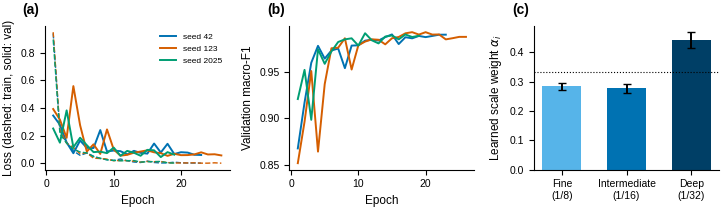

learned alpha (mean over seeds): [0.283 0.276 0.44 ] +- [0.011 0.016 0.026]


In [17]:
# Figure 5: training dynamics of the full model + learned multi-scale weights
fig, axes = plt.subplots(1, 3, figsize=(7.4, 2.3))
for s_i, seed in enumerate(CFG["seeds"]):
    h = RES[(FULL, seed)]["history"]
    axes[0].plot(h.epoch, h.train_loss, color=OKABE[s_i], ls="--", lw=1); axes[0].plot(h.epoch, h.val_loss, color=OKABE[s_i], label=f"seed {seed}")
    axes[1].plot(h.epoch, h.val_f1, color=OKABE[s_i])
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Loss (dashed: train, solid: val)"); axes[0].legend(fontsize=6); panel(axes[0], "a")
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Validation macro-F1"); panel(axes[1], "b")
al = np.array([RES[(FULL, s)]["alpha"] for s in CFG["seeds"]])
axes[2].bar(["Fine\n(1/8)", "Intermediate\n(1/16)", "Deep\n(1/32)"], al.mean(0), yerr=al.std(0), color=["#56B4E9", "#0072B2", "#003f66"], capsize=3, width=0.6)
axes[2].axhline(1 / 3, color="k", ls=":", lw=0.8); axes[2].set_ylabel("Learned scale weight $\\alpha_i$"); panel(axes[2], "c")
plt.tight_layout(); save_fig(fig, "Fig05_training_dynamics_and_scale_weights")
print("learned alpha (mean over seeds):", al.mean(0).round(3), "+-", al.std(0).round(3))

## 7. Main results on the BRISC2025 test set
*Primary estimate*: mean +- SD over independent training seeds (captures training variance). *Ensemble estimate*: average of the seed-wise softmax outputs with **non-parametric bootstrap 95 % CIs** (2,000 resamples of the test images, captures test-sampling variance).

In [18]:
def get_P(name, split, seed=None, calibrated=False):
    key = {"val": "val_logits", "test": "test_logits", "ext": "ext_logits"}[split]
    seeds = [seed] if seed is not None else CFG["seeds"]
    Ps = [softmax_np(RES[(name, s)][key], RES[(name, s)].get("T", 1.0) if calibrated else 1.0) for s in seeds]
    return Ps[0] if seed is not None else np.mean(Ps, 0)

Y = {"val": y_va, "test": y_te, "ext": df_ext.y.values.astype(np.int64) if HAS_EXT else np.zeros(0, np.int64)}

def metrics_from_probs(y, P, full=True):
    pred = P.argmax(1)
    pr, rc, f1, _ = precision_recall_fscore_support(y, pred, labels=list(range(N_CLS)), zero_division=0)
    d = dict(accuracy=float((pred == y).mean()), macro_f1=float(f1.mean()))
    if full:
        d.update(balanced_acc=balanced_accuracy_score(y, pred), precision=float(pr.mean()), recall=float(rc.mean()),
                 mcc=matthews_corrcoef(y, pred), kappa=cohen_kappa_score(y, pred))
    try:   d["auc"] = roc_auc_score(y, P, multi_class="ovr", average="macro", labels=list(range(N_CLS)))
    except Exception: d["auc"] = np.nan
    return d

def boot_ci(y, P, n=None, seed=0, keys=("accuracy", "macro_f1", "mcc", "auc")):
    n = n or CFG["n_boot"]; rng = np.random.default_rng(seed); N = len(y)
    acc = {k: [] for k in keys}
    for _ in range(n):
        idx = rng.integers(0, N, N)
        m = metrics_from_probs(y[idx], P[idx], full=("mcc" in keys))
        for k in keys: acc[k].append(m[k])
    return {k: (float(np.nanpercentile(v, 2.5)), float(np.nanpercentile(v, 97.5))) for k, v in acc.items()}

def fmt_ci(v, ci): return f"{100*v:.2f} [{100*ci[0]:.2f}, {100*ci[1]:.2f}]"

rows, MAIN_CI = [], {}
for name in RUN_VARIANTS:
    per_seed = pd.DataFrame([metrics_from_probs(y_te, get_P(name, "test", s)) for s in CFG["seeds"]])
    Pe = get_P(name, "test"); me = metrics_from_probs(y_te, Pe); ci = boot_ci(y_te, Pe); MAIN_CI[name] = ci
    rows.append({"Variant": name,
                 "Acc (%) mean+-SD": f"{100*per_seed.accuracy.mean():.2f} +- {100*per_seed.accuracy.std(ddof=0):.2f}",
                 "Macro-F1 (%) mean+-SD": f"{100*per_seed.macro_f1.mean():.2f} +- {100*per_seed.macro_f1.std(ddof=0):.2f}",
                 "MCC mean+-SD": f"{per_seed.mcc.mean():.3f} +- {per_seed.mcc.std(ddof=0):.3f}",
                 "AUC mean+-SD": f"{per_seed.auc.mean():.4f} +- {per_seed.auc.std(ddof=0):.4f}",
                 "Ensemble Acc (%) [95% CI]": fmt_ci(me["accuracy"], ci["accuracy"]),
                 "Ensemble Macro-F1 (%) [95% CI]": fmt_ci(me["macro_f1"], ci["macro_f1"]),
                 "Ensemble AUC [95% CI]": f"{me['auc']:.4f} [{ci['auc'][0]:.4f}, {ci['auc'][1]:.4f}]",
                 "Params (M)": round(n_par[name], 2)})
T4 = pd.DataFrame(rows).set_index("Variant"); save_table(T4, "T4_main_results_BRISC_test"); display(T4.T)

Variant,DenseNet121,DenseNet121+AMEM,MS-fixed,MS-fixed+Attn,AMSR-CNN,AMSR-CNN (no AMEM)
Acc (%) mean+-SD,99.10 +- 0.57,98.50 +- 0.41,98.53 +- 0.12,98.60 +- 0.14,98.30 +- 0.37,99.03 +- 0.17
Macro-F1 (%) mean+-SD,99.21 +- 0.52,98.68 +- 0.36,98.68 +- 0.09,98.75 +- 0.14,98.50 +- 0.34,99.12 +- 0.19
MCC mean+-SD,0.988 +- 0.008,0.980 +- 0.006,0.980 +- 0.002,0.981 +- 0.002,0.977 +- 0.005,0.987 +- 0.002
AUC mean+-SD,0.9995 +- 0.0003,0.9993 +- 0.0005,0.9992 +- 0.0004,0.9995 +- 0.0003,0.9990 +- 0.0005,0.9993 +- 0.0002
Ensemble Acc (%) [95% CI],"99.60 [99.20, 99.90]","98.80 [98.10, 99.40]","99.00 [98.30, 99.50]","98.80 [98.00, 99.40]","98.70 [98.00, 99.30]","99.10 [98.50, 99.60]"
Ensemble Macro-F1 (%) [95% CI],"99.65 [99.28, 99.92]","98.95 [98.29, 99.48]","99.12 [98.52, 99.58]","98.94 [98.26, 99.48]","98.87 [98.22, 99.40]","99.20 [98.65, 99.65]"
Ensemble AUC [95% CI],"0.9995 [0.9987, 1.0000]","0.9995 [0.9987, 1.0000]","0.9995 [0.9990, 0.9999]","0.9997 [0.9992, 1.0000]","0.9997 [0.9991, 1.0000]","0.9997 [0.9994, 1.0000]"
Params (M),6.96,6.96,8.33,8.36,8.36,8.36


[fig] Fig06_main_results_confusion_ROC_PR.png  2551x2231px  dpi=(360, 360)


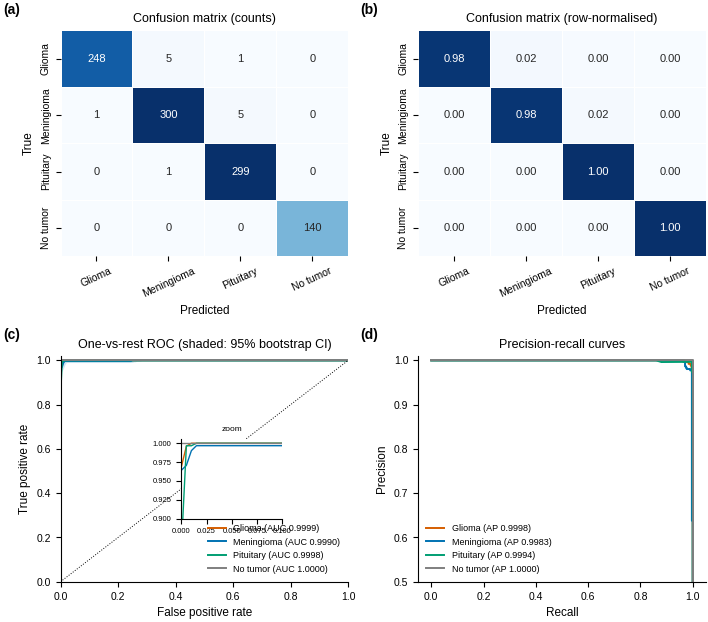

,Precision,Recall (sensitivity),F1,Support,AUC,Specificity
Glioma,0.995984,0.976378,0.986083,254,0.999916,0.998660
Meningioma,0.980392,0.980392,0.980392,306,0.998955,0.991354
Pituitary,0.980328,0.996667,0.988430,300,0.999781,0.991429
No tumor,1.000000,1.000000,1.000000,140,1.000000,1.000000


In [19]:
# Figure 6: confusion matrices, ROC (bootstrap band), PR curves of the final model (seed ensemble)
P_full = get_P(FULL, "test"); pred_full = P_full.argmax(1)
cmat = confusion_matrix(y_te, pred_full, labels=range(N_CLS)); cmn = cmat / np.maximum(cmat.sum(1, keepdims=True), 1)
Y1 = label_binarize(y_te, classes=range(N_CLS)); fpr_grid = np.linspace(0, 1, 201)

def roc_interp(y1, p):
    fpr, tpr, _ = roc_curve(y1, p); return np.interp(fpr_grid, fpr, tpr)

rng = np.random.default_rng(1); nb_roc = min(300, CFG["n_boot"]); bands = {c: [] for c in range(N_CLS)}
for _ in range(nb_roc):
    idx = rng.integers(0, len(y_te), len(y_te))
    for c in range(N_CLS):
        if Y1[idx, c].min() != Y1[idx, c].max(): bands[c].append(roc_interp(Y1[idx, c], P_full[idx, c]))

fig, axes = plt.subplots(2, 2, figsize=(7.2, 6.4))
for ax, M, ttl, fmt_, L in [(axes[0, 0], cmat, "Confusion matrix (counts)", "d", "a"), (axes[0, 1], cmn, "Confusion matrix (row-normalised)", ".2f", "b")]:
    sns.heatmap(M, annot=True, fmt=fmt_, cmap="Blues", cbar=False, ax=ax, annot_kws={"size": 8}, linewidths=0.5, linecolor="white",
                xticklabels=[CLS_PRETTY[c] for c in CLASSES], yticklabels=[CLS_PRETTY[c] for c in CLASSES])
    ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title(ttl); panel(ax, L, dx=-0.2); ax.tick_params(axis="x", rotation=25)
ax = axes[1, 0]; panel(ax, "c", dx=-0.2)
for c in range(N_CLS):
    ax.plot(fpr_grid, roc_interp(Y1[:, c], P_full[:, c]), color=CLS_COL[CLASSES[c]], label=f"{CLS_PRETTY[CLASSES[c]]} (AUC {roc_auc_score(Y1[:, c], P_full[:, c]):.4f})")
    if bands[c]:
        b = np.array(bands[c]); ax.fill_between(fpr_grid, np.percentile(b, 2.5, 0), np.percentile(b, 97.5, 0), color=CLS_COL[CLASSES[c]], alpha=0.18, lw=0)
ax.plot([0, 1], [0, 1], "k:", lw=0.7); ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate"); ax.set_title("One-vs-rest ROC (shaded: 95% bootstrap CI)")
ax.legend(loc="lower right", fontsize=6.5); ax.set_xlim(0, 1); ax.set_ylim(0, 1.02)
inset = ax.inset_axes([0.42, 0.28, 0.35, 0.35]);
for c in range(N_CLS): inset.plot(fpr_grid, roc_interp(Y1[:, c], P_full[:, c]), color=CLS_COL[CLASSES[c]], lw=1)
inset.set_xlim(0, 0.1); inset.set_ylim(0.9, 1.005); inset.tick_params(labelsize=5.5); inset.set_title("zoom", fontsize=6)
ax = axes[1, 1]; panel(ax, "d", dx=-0.2)
for c in range(N_CLS):
    p_, r_, _ = precision_recall_curve(Y1[:, c], P_full[:, c])
    ax.plot(r_, p_, color=CLS_COL[CLASSES[c]], label=f"{CLS_PRETTY[CLASSES[c]]} (AP {average_precision_score(Y1[:, c], P_full[:, c]):.4f})")
ax.set_xlabel("Recall"); ax.set_ylabel("Precision"); ax.set_title("Precision-recall curves"); ax.legend(loc="lower left", fontsize=6.5); ax.set_ylim(0.5, 1.01)
plt.tight_layout(); save_fig(fig, "Fig06_main_results_confusion_ROC_PR")

pr_, rc_, f1_, sup_ = precision_recall_fscore_support(y_te, pred_full, labels=range(N_CLS), zero_division=0)
T5 = pd.DataFrame({"Precision": pr_, "Recall (sensitivity)": rc_, "F1": f1_, "Support": sup_,
                   "AUC": [roc_auc_score(Y1[:, c], P_full[:, c]) for c in range(N_CLS)]},
                  index=[CLS_PRETTY[c] for c in CLASSES])
# specificity per class
T5["Specificity"] = [(cmat.sum() - cmat[c].sum() - cmat[:, c].sum() + cmat[c, c]) / (cmat.sum() - cmat[c].sum()) for c in range(N_CLS)]
save_table(T5, "T5_per_class_AMSR_CNN"); display(T5)

## 8. Explainability: Grad-CAM++, Integrated Gradients, Occlusion
All methods explain the **predicted class logit/probability of one trained AMSR-CNN** (first seed) and are computed in the original intensity space.
* **Grad-CAM++** on the *tumor-relevant feature representation* (output of the refine block).
* **Integrated Gradients** (zero baseline, midpoint Riemann sum, absolute attribution aggregated over pixels and smoothed).
* **Occlusion** (32x32 patch, stride 16, black fill; map = mean drop of the class probability).

Beyond qualitative overlays we **quantify** them: (i) *localisation* against radiologist masks (pointing game, energy inside tumor, IoU of the top-area pixels) and (ii) *faithfulness* (deletion / insertion AUC, 21 steps, blurred baseline). A random-map reference is included.

In [20]:
XAI_SEED = CFG["seeds"][0]
xmodel = load_trained(FULL, XAI_SEED); xmodel.eval()
for p_ in xmodel.parameters(): p_.requires_grad_(False)

def norm01(m):
    m = m - m.min(); return m / (m.max() + 1e-8)

def gradcam_pp(model, x, target):
    acts = []
    h = model.refine.register_forward_hook(lambda m_, i_, o_: acts.append(o_))
    with torch.enable_grad():
        out = model(x.clone().requires_grad_(True)); A = acts[0]; h.remove()   # input needs grad so the graph exists (weights are frozen)
        grads = torch.autograd.grad(out.gather(1, target[:, None]).sum(), A)[0]
    g2, g3 = grads ** 2, grads ** 3
    den = 2 * g2 + (A * g3).sum((2, 3), keepdim=True); den = torch.where(den != 0, den, torch.ones_like(den))
    w = ((g2 / den) * F.relu(grads)).sum((2, 3), keepdim=True)
    cam = F.relu((w * A).sum(1, keepdim=True).detach())
    cam = F.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False)[:, 0].cpu().numpy()
    return np.stack([norm01(c) for c in cam])

def integrated_gradients(model, x, target, steps=None):
    steps = steps or CFG["ig_steps"]; total = torch.zeros_like(x)
    for k in range(steps):
        xi = (x * (k + 0.5) / steps).requires_grad_(True)
        with torch.enable_grad():
            g = torch.autograd.grad(model(xi).gather(1, target[:, None]).sum(), xi)[0]
        total += g
    ig = (x * total / steps).abs()[:, 0].cpu().numpy()
    return np.stack([norm01(cv2.GaussianBlur(a, (0, 0), 3)) for a in ig])

@torch.no_grad()
def occlusion_map(model, x1, target, patch=None, stride=None):
    patch, stride = patch or CFG["occ_patch"], stride or CFG["occ_stride"]; H = x1.shape[-1]
    base = F.softmax(model(x1), 1)[0, target].item()
    pos = list(range(0, H - patch + 1, stride)); pos = pos + ([H - patch] if pos[-1] != H - patch else [])
    boxes = [(i, j) for i in pos for j in pos]; xs = x1.repeat(len(boxes), 1, 1, 1)
    for n_, (i, j) in enumerate(boxes): xs[n_, :, i:i + patch, j:j + patch] = 0
    pr = torch.cat([F.softmax(model(xs[k:k + 64]), 1)[:, target] for k in range(0, len(xs), 64)]).cpu().numpy()
    acc, cnt = np.zeros((H, H)), np.zeros((H, H))
    for n_, (i, j) in enumerate(boxes):
        acc[i:i + patch, j:j + patch] += base - pr[n_]; cnt[i:i + patch, j:j + patch] += 1
    return norm01(np.clip(acc / np.maximum(cnt, 1), 0, None))

def explain_batch(idxs):
    """idxs: positions within the test set. Returns dict(method -> (n,H,W)), predicted classes."""
    x = torch.from_numpy(Xam_b[te_i][idxs]).to(DEVICE).float().div_(255).unsqueeze(1)
    with torch.no_grad(): tgt = xmodel(x).argmax(1)
    maps = {"Grad-CAM++": gradcam_pp(xmodel, x, tgt), "Integrated Gradients": integrated_gradients(xmodel, x, tgt),
            "Occlusion": np.stack([occlusion_map(xmodel, x[i:i + 1], int(tgt[i])) for i in range(len(x))])}
    return maps, tgt.cpu().numpy(), x

# --- sample tumor test slices (correctly classified, with GT mask), stratified over the three tumor classes
has_gt = GT_test.reshape(len(GT_test), -1).any(1)
pred_x = np.argmax(softmax_np(RES[(FULL, XAI_SEED)]["test_logits"]), 1)
rng = np.random.default_rng(7); sel = []
per_c = max(1, CFG["xai_n"] // 3)
for c in range(3):
    cand = np.where((y_te == c) & has_gt & (pred_x == c))[0]
    sel += list(rng.choice(cand, min(per_c, len(cand)), replace=False)) if len(cand) else []
if len(sel) == 0:                                   # only possible for a (near-)untrained model, e.g. in QUICK_RUN
    sel = list(np.where(has_gt)[0][:6]); print("!! no correctly classified tumor slices: using first masked slices")
sel = np.array(sel)

t0 = time.time(); MAPS = defaultdict(list); BS = 8
for i in tqdm(range(0, len(sel), BS), desc="XAI", leave=False):
    m_, _, _ = explain_batch(sel[i:i + BS])
    for k, v in m_.items(): MAPS[k].append(v)
MAPS = {k: np.concatenate(v) for k, v in MAPS.items()}
MAPS["Random"] = np.stack([norm01(cv2.GaussianBlur(np.random.default_rng(i).random((IMG, IMG)).astype(np.float32), (0, 0), 8)) for i in range(len(sel))])
print(f"XAI maps for {len(sel)} images in {time.time()-t0:.0f}s")

XAI:   0%|          | 0/15 [00:00<?, ?it/s]

XAI maps for 120 images in 107s


In [21]:
# ---- quantitative evaluation: localisation + faithfulness
def localisation(maps, gts):
    pg, en, iou = [], [], []
    for m, g in zip(maps, gts):
        g = g.astype(bool); gd = cv2.dilate(g.astype(np.uint8), ELL(7)) > 0
        pg.append(float(gd.flat[np.argmax(m)])); en.append(float(m[g].sum() / (m.sum() + 1e-8)))
        k = max(1, int(g.sum())); thr = np.partition(m.ravel(), -k)[-k]
        pm = m >= thr; iou.append(float((pm & g).sum() / max((pm | g).sum(), 1)))
    return np.array(pg), np.array(en), np.array(iou)

_trapz = getattr(np, "trapezoid", None) or np.trapz

@torch.no_grad()
def del_ins_auc(model, x1, m, target, steps=21):
    H = x1.shape[-1]; blur = torch.from_numpy(cv2.GaussianBlur(x1[0, 0].cpu().numpy(), (0, 0), 8)).to(DEVICE)[None, None]
    rank = np.empty(H * H, np.int64); rank[np.argsort(-m.ravel(), kind="stable")] = np.arange(H * H)
    fr = np.linspace(0, 1, steps); out = {}
    for mode in ("deletion", "insertion"):
        xs = []
        for f in fr:
            sel_ = torch.from_numpy((rank < f * H * H).reshape(H, H)).to(DEVICE)[None, None]
            xs.append(torch.where(sel_, blur, x1) if mode == "deletion" else torch.where(sel_, x1, blur))
        pr = F.softmax(model(torch.cat(xs)), 1)[:, target].cpu().numpy(); out[mode] = (pr, float(_trapz(pr, fr)))
    return out

xs_sel = torch.from_numpy(Xam_b[te_i][sel]).to(DEVICE).float().div_(255).unsqueeze(1)
tg_sel = torch.from_numpy(pred_x[sel]).to(DEVICE)
XQ, CURVES = {}, {}
for meth, mm in MAPS.items():
    pg, en, iou = localisation(mm, GT_test[sel])
    res_ = [del_ins_auc(xmodel, xs_sel[i:i + 1], mm[i], int(tg_sel[i])) for i in range(len(sel))]
    XQ[meth] = pd.DataFrame(dict(pointing=pg, energy=en, iou=iou, deletion=[r["deletion"][1] for r in res_], insertion=[r["insertion"][1] for r in res_]))
    CURVES[meth] = (np.mean([r["deletion"][0] for r in res_], 0), np.mean([r["insertion"][0] for r in res_], 0))

def mean_ci(v):
    v = np.asarray(v, float); h = stats.sem(v) * stats.t.ppf(0.975, max(len(v) - 1, 1)) if len(v) > 1 else 0.0
    return v.mean(), h
T6 = pd.DataFrame({m: {c: "%.3f +- %.3f" % mean_ci(df_[c]) for c in df_.columns} for m, df_ in XQ.items()}).T
T6.columns = ["Pointing game", "Energy in tumor", "IoU (top-area)", "Deletion AUC (lower better)", "Insertion AUC (higher better)"]
save_table(T6, "T6_XAI_quantitative", float_fmt="%s", caption="Quantitative XAI evaluation (mean +- 95% CI)."); display(T6)

,Pointing game,Energy in tumor,IoU (top-area),Deletion AUC (lower better),Insertion AUC (higher better)
Grad-CAM++,0.533 +- 0.091,0.103 +- 0.019,0.291 +- 0.054,0.475 +- 0.043,0.942 +- 0.012
Integrated Gradients,0.733 +- 0.080,0.158 +- 0.026,0.427 +- 0.052,0.455 +- 0.038,0.904 +- 0.021
Occlusion,0.400 +- 0.089,0.244 +- 0.052,0.196 +- 0.041,0.574 +- 0.042,0.882 +- 0.023
Random,0.025 +- 0.028,0.021 +- 0.004,0.010 +- 0.006,0.685 +- 0.042,0.669 +- 0.047


[fig] Fig07_explainability_qualitative.png  2303x2489px  dpi=(360, 360)


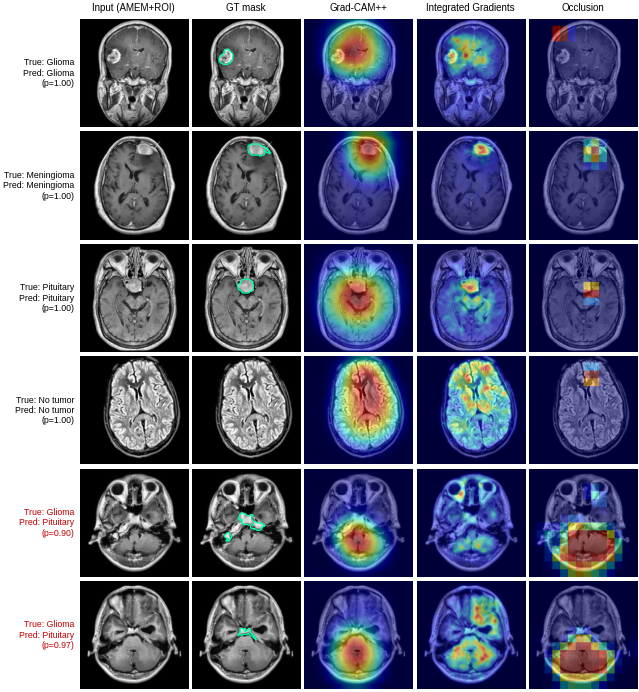

[fig] Fig08_explainability_quantitative.png  2602x748px  dpi=(360, 360)


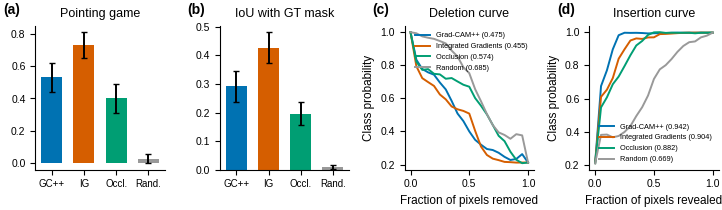

In [22]:
# ---- Figure 7: qualitative XAI (one correct example per class + misclassified test slices)
def overlay(img, cam, alpha=0.45):
    rgb = np.repeat(img[..., None], 3, 2) / 255.0; heat = plt.get_cmap("jet")(cam)[..., :3]
    return np.clip((1 - alpha) * rgb + alpha * heat, 0, 1)

rows_idx = []
for c in range(N_CLS):
    cand = np.where((y_te == c) & (pred_x == c) & (has_gt if c < 3 else True))[0]
    if not len(cand): cand = np.where(y_te == c)[0]
    rows_idx.append((cand[len(cand) // 3], "correct" if pred_x[cand[len(cand) // 3]] == c else "wrong"))
wrong = np.where(pred_x != y_te)[0]
for w in wrong[:2]: rows_idx.append((w, "wrong"))
idxs = np.array([r[0] for r in rows_idx]); mq, tq, _ = explain_batch(idxs)
cols = ["Input (AMEM+ROI)", "GT mask", "Grad-CAM++", "Integrated Gradients", "Occlusion"]
fig, axes = plt.subplots(len(idxs), 5, figsize=(7.2, 1.45 * len(idxs)))
axes = np.atleast_2d(axes)
for r, (i, kind) in enumerate(rows_idx):
    img = Xam_b[te_i][i]; P_ = softmax_np(RES[(FULL, XAI_SEED)]["test_logits"][i:i + 1])[0]
    axes[r, 0].imshow(img, cmap="gray"); axes[r, 1].imshow(img, cmap="gray")
    if GT_test[i].any(): axes[r, 1].contour(GT_test[i], levels=[0.5], colors="#00FFAA", linewidths=0.9)
    for c_, meth in enumerate(["Grad-CAM++", "Integrated Gradients", "Occlusion"]): axes[r, 2 + c_].imshow(overlay(img, mq[meth][r]))
    axes[r, 0].set_ylabel(f"True: {CLS_PRETTY[CLASSES[y_te[i]]]}\nPred: {CLS_PRETTY[CLASSES[tq[r]]]}\n(p={P_.max():.2f})", fontsize=6.3,
                          color="k" if kind == "correct" else "#C00000", rotation=0, ha="right", va="center", labelpad=4)
    for a in axes[r]: a.set_xticks([]); a.set_yticks([]); [s.set_visible(False) for s in a.spines.values()]
for c_, t in enumerate(cols): axes[0, c_].set_title(t, fontsize=7)
plt.subplots_adjust(wspace=0.03, hspace=0.04); save_fig(fig, "Fig07_explainability_qualitative")

# ---- Figure 8: quantitative XAI
fig, axes = plt.subplots(1, 4, figsize=(7.4, 2.3)); mcol = {"Grad-CAM++": "#0072B2", "Integrated Gradients": "#D55E00", "Occlusion": "#009E73", "Random": "#999999"}
for ax, key, ttl, L in zip(axes[:2], ["pointing", "iou"], ["Pointing game", "IoU with GT mask"], "ab"):
    mv = [mean_ci(XQ[m][key]) for m in XQ]
    ax.bar(range(len(XQ)), [v[0] for v in mv], yerr=[v[1] for v in mv], color=[mcol[m] for m in XQ], capsize=2.5, width=0.65)
    ax.set_xticks(range(len(XQ))); ax.set_xticklabels(["GC++", "IG", "Occl.", "Rand."], fontsize=7); ax.set_title(ttl); panel(ax, L, dx=-0.25)
fr = np.linspace(0, 1, 21)
for ax, j, ttl, L in zip(axes[2:], [0, 1], ["Deletion curve", "Insertion curve"], "cd"):
    for m in XQ: ax.plot(fr, CURVES[m][j], color=mcol[m], label=f"{m} ({XQ[m]['deletion' if j == 0 else 'insertion'].mean():.3f})")
    ax.set_xlabel("Fraction of pixels " + ("removed" if j == 0 else "revealed")); ax.set_ylabel("Class probability"); ax.set_title(ttl); panel(ax, L, dx=-0.25)
axes[3].legend(fontsize=5.3, loc="lower right"); axes[2].legend(fontsize=5.3, loc="upper right")
plt.tight_layout(); save_fig(fig, "Fig08_explainability_quantitative")

## 9. Reliability: confidence, entropy, calibration, uncertainty
* **Confidence** = max softmax probability; **predictive entropy** H[p].
* **Calibration**: ECE (15 equal-width bins), MCE, Brier score and NLL, before and after **temperature scaling** (T fitted on the validation split of each model only).
* **Uncertainty**: (i) Monte-Carlo dropout (T passes through the dropout head), (ii) deep ensemble over seeds. Total uncertainty = entropy of the mean prediction, **epistemic** = mutual information (entropy minus mean per-pass entropy).
* **Selective prediction**: risk-coverage curves and AURC for each uncertainty score.

In [23]:
def ece_mce(P, y, bins=None):
    bins = bins or CFG["ece_bins"]; conf, pred = P.max(1), P.argmax(1); corr = (pred == y).astype(float)
    edges = np.linspace(0, 1, bins + 1); e, mce, rows = 0.0, 0.0, []
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.sum():
            gap = abs(corr[m].mean() - conf[m].mean()); e += m.mean() * gap; mce = max(mce, gap); rows.append((conf[m].mean(), corr[m].mean(), m.sum()))
    return e, mce, np.array(rows)

def nll(P, y): return float(-np.log(P[np.arange(len(y)), y] + 1e-12).mean())
def brier(P, y): return float(((P - np.eye(N_CLS)[y]) ** 2).sum(1).mean())
def entropy(P): return -(P * np.log(P + 1e-12)).sum(-1)

def fit_temperature(logits, y):
    z, t = torch.tensor(logits, dtype=torch.float32), torch.tensor(y)
    lt = torch.zeros(1, requires_grad=True); opt = torch.optim.LBFGS([lt], lr=0.1, max_iter=200)
    def closure():
        opt.zero_grad(); l = F.cross_entropy(z / lt.exp(), t); l.backward(); return l
    opt.step(closure); return float(lt.exp())

for key_, r in RES.items(): r["T"] = fit_temperature(r["val_logits"], y_va)
print({k[0] + f"/s{k[1]}": round(v["T"], 2) for k, v in list(RES.items())[:6]}, "...")

rows = []
for name in RUN_VARIANTS:
    for cal in (False, True):
        vals = []
        for s in CFG["seeds"]:
            P = get_P(name, "test", s, calibrated=cal); e, m, _ = ece_mce(P, y_te)
            vals.append(dict(ECE=e, MCE=m, NLL=nll(P, y_te), Brier=brier(P, y_te)))
        v = pd.DataFrame(vals); Pe = get_P(name, "test", None, calibrated=cal); ee = ece_mce(Pe, y_te)
        rows.append({"Variant": name, "Temp. scaling": "yes" if cal else "no", **{k: f"{v[k].mean():.4f} +- {v[k].std(ddof=0):.4f}" for k in v.columns},
                     "Ensemble ECE": round(ee[0], 4), "Ensemble NLL": round(nll(Pe, y_te), 4)})
T7 = pd.DataFrame(rows).set_index(["Variant", "Temp. scaling"]); save_table(T7, "T7_calibration"); display(T7)

{'DenseNet121/s42': 1.51, 'DenseNet121/s123': 1.57, 'DenseNet121/s2025': 1.24, 'DenseNet121+AMEM/s42': 1.77, 'DenseNet121+AMEM/s123': 1.54, 'DenseNet121+AMEM/s2025': 1.32} ...


ECE               MCE  \
Variant            Temp. scaling                                       
DenseNet121        no             0.0075 +- 0.0033  0.5260 +- 0.2458   
                   yes            0.0068 +- 0.0033  0.5247 +- 0.0405   
DenseNet121+AMEM   no             0.0118 +- 0.0015  0.5568 +- 0.0899   
                   yes            0.0091 +- 0.0016  0.5299 +- 0.0821   
MS-fixed           no             0.0126 +- 0.0002  0.8095 +- 0.0951   
                   yes            0.0074 +- 0.0012  0.5017 +- 0.1757   
MS-fixed+Attn      no             0.0125 +- 0.0016  0.7124 +- 0.1811   
                   yes            0.0074 +- 0.0018  0.5101 +- 0.1241   
AMSR-CNN           no             0.0132 +- 0.0009  0.5444 +- 0.1530   
                   yes            0.0073 +- 0.0022  0.5758 +- 0.0598   
AMSR-CNN (no AMEM) no             0.0089 +- 0.0014  0.5115 +- 0.2883   
                   yes            0.0060 +- 0.0027  0.5899 +- 0.0804   

                                               NLL             Brier  \
Variant            Temp. scaling                                       
DenseNet121        no             0.0479 +- 0.0150  0.0163 +- 0.0087   
                   yes            0.0389 +- 0.0154  0.0162 +- 0.0084   
DenseNet121+AMEM   no             0.0617 +- 0.0130  0.0252 +- 0.0050   
                   yes            0.0506 +- 0.0120  0.0240 +- 0.0050   
MS-fixed           no             0.0861 +- 0.0051  0.0249 +- 0.0008   
                   yes            0.0509 +- 0.0029  0.0230 +- 0.0003   
MS-fixed+Attn      no             0.0874 +- 0.0183  0.0245 +- 0.0033   
                   yes            0.0488 +- 0.0101  0.0224 +- 0.0035   
AMSR-CNN           no             0.0977 +- 0.0151  0.0280 +- 0.0039   
                   yes            0.0593 +- 0.0114  0.0262 +- 0.0039   
AMSR-CNN (no AMEM) no             0.0726 +- 0.0040  0.0181 +- 0.0032   
                   yes            0.0396 +- 0.0076  0.0163 +- 0.0038   

                                  Ensemble ECE  Ensemble NLL  
Variant            Temp. scaling                              
DenseNet121        no                   0.0088        0.0323  
                   yes                  0.0070        0.0288  
DenseNet121+AMEM   no                   0.0094        0.0364  
                   yes                  0.0092        0.0354  
MS-fixed           no                   0.0084        0.0519  
                   yes                  0.0080        0.0382  
MS-fixed+Attn      no                   0.0098        0.0494  
                   yes                  0.0055        0.0374  
AMSR-CNN           no                   0.0055        0.0390  
                   yes                  0.0125        0.0381  
AMSR-CNN (no AMEM) no                   0.0086        0.0410  
                   yes                  0.0052        0.0302

In [24]:
# ---- Monte-Carlo dropout + deep ensemble uncertainty for the final model
@torch.no_grad()
def embeddings(model, X_u8, bs=128):
    out = []
    for i in range(0, len(X_u8), bs):
        xb = torch.from_numpy(X_u8[i:i + bs]).to(DEVICE).float().div_(255).unsqueeze(1)
        out.append(model(xb, return_embedding=True)[1].float().cpu())
    return torch.cat(out)

@torch.no_grad()
def mc_dropout_probs(model, X_u8, T=None):
    T = T or CFG["mc_T"]; emb = embeddings(model.eval(), X_u8).to(DEVICE); model.head.train()
    P = torch.stack([F.softmax(model.head(emb), 1) for _ in range(T)]).cpu().numpy(); model.head.eval(); return P

torch.manual_seed(0)
P_mc = mc_dropout_probs(xmodel, Xam_b[te_i])                                          # (T,N,C)
P_ens_s = np.stack([get_P(FULL, "test", s, calibrated=True) for s in CFG["seeds"]])     # (S,N,C), temperature-scaled
def decompose(Ps):
    mean = Ps.mean(0); tot = entropy(mean); alea = entropy(Ps).mean(0); return mean, tot, alea, np.clip(tot - alea, 0, None)
P_mcm, H_mc, A_mc, MI_mc = decompose(P_mc)
P_dem, H_de, A_de, MI_de = decompose(P_ens_s) if len(CFG["seeds"]) > 1 else (P_ens_s[0], entropy(P_ens_s[0]), entropy(P_ens_s[0]), np.zeros(len(y_te)))
P_cal_ens = get_P(FULL, "test", None, calibrated=True); P_unc_ens = get_P(FULL, "test", None, calibrated=False)

def risk_coverage(score, correct):
    order = np.argsort(score, kind="stable"); err = 1 - correct[order]
    cov = np.arange(1, len(err) + 1) / len(err); risk = np.cumsum(err) / np.arange(1, len(err) + 1); return cov, risk, float(risk.mean())

corr_ens = (P_cal_ens.argmax(1) == y_te).astype(float)
U = {"1 - confidence": 1 - P_cal_ens.max(1), "Predictive entropy": entropy(P_cal_ens), "MC-dropout MI": MI_mc, "Ensemble MI": MI_de}
unc_rows = []
for k, sc in U.items():
    auroc = roc_auc_score(1 - corr_ens, sc) if 0 < corr_ens.sum() < len(corr_ens) else np.nan
    _, _, aurc = risk_coverage(sc, corr_ens)
    unc_rows.append({"Uncertainty score": k, "AUROC (error detection)": auroc, "AURC (lower better)": aurc,
                     "Acc @90% coverage": corr_ens[np.argsort(sc)][:int(.9 * len(sc))].mean(), "Acc @80% coverage": corr_ens[np.argsort(sc)][:int(.8 * len(sc))].mean()})
T8 = pd.DataFrame(unc_rows).set_index("Uncertainty score"); save_table(T8, "T8_uncertainty_selective_prediction"); display(T8)

,AUROC (error detection),AURC (lower better),Acc @90% coverage,Acc @80% coverage
Uncertainty score,,,,
1 - confidence,0.965630,0.000615,0.998889,0.99875
Predictive entropy,0.962123,0.000661,0.998889,0.99875
MC-dropout MI,0.857610,0.002576,0.995556,0.99625
Ensemble MI,0.973112,0.000488,0.998889,0.99875


[fig] Fig09_reliability_calibration_uncertainty.png  2616x1690px  dpi=(360, 360)


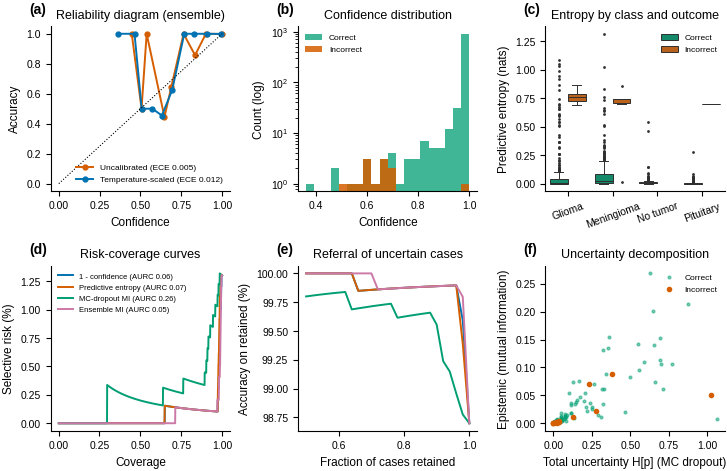

In [25]:
# ---- Figure 9: reliability panel
fig, axes = plt.subplots(2, 3, figsize=(7.4, 4.9)); axes = axes.ravel()
ax = axes[0]; panel(ax, "a")
for P, lab, col in [(P_unc_ens, "Uncalibrated", "#D55E00"), (P_cal_ens, "Temperature-scaled", "#0072B2")]:
    e, _, rr = ece_mce(P, y_te); ax.plot(rr[:, 0], rr[:, 1], "o-", ms=3.5, color=col, label=f"{lab} (ECE {e:.3f})")
ax.plot([0, 1], [0, 1], "k:", lw=0.8); ax.set_xlabel("Confidence"); ax.set_ylabel("Accuracy"); ax.set_title("Reliability diagram (ensemble)"); ax.legend(fontsize=6)
ax = axes[1]; panel(ax, "b"); conf = P_cal_ens.max(1)
bins_ = np.linspace(conf.min() if conf.min() < 0.9 else 0.25, 1, 21)
ax.hist(conf[corr_ens == 1], bins=bins_, color="#009E73", alpha=0.75, label="Correct", log=True)
if (corr_ens == 0).any(): ax.hist(conf[corr_ens == 0], bins=bins_, color="#D55E00", alpha=0.85, label="Incorrect", log=True)
ax.set_xlabel("Confidence"); ax.set_ylabel("Count (log)"); ax.set_title("Confidence distribution"); ax.legend(fontsize=6)
ax = axes[2]; panel(ax, "c")
dd = pd.DataFrame({"H": entropy(P_cal_ens), "Outcome": np.where(corr_ens == 1, "Correct", "Incorrect"), "Class": [CLS_PRETTY[CLASSES[i]] for i in y_te]})
sns.boxplot(data=dd, x="Class", y="H", hue="Outcome", palette={"Correct": "#009E73", "Incorrect": "#D55E00"}, fliersize=1, linewidth=0.7, ax=ax)
ax.set_ylabel("Predictive entropy (nats)"); ax.set_xlabel(""); ax.set_title("Entropy by class and outcome"); ax.tick_params(axis="x", rotation=20); ax.legend(fontsize=6)
ax = axes[3]; panel(ax, "d")
for (k, sc), col in zip(U.items(), OKABE):
    cov, risk, aurc = risk_coverage(sc, corr_ens); ax.plot(cov, risk * 100, color=col, label=f"{k} (AURC {aurc*100:.2f})")
ax.set_xlabel("Coverage"); ax.set_ylabel("Selective risk (%)"); ax.set_title("Risk-coverage curves"); ax.legend(fontsize=5.5)
ax = axes[4]; panel(ax, "e")
for (k, sc), col in zip(U.items(), OKABE):
    o = np.argsort(sc); ks = np.linspace(0.5, 1, 26); ax.plot(ks, [corr_ens[o][:max(1, int(f * len(o)))].mean() * 100 for f in ks], color=col, label=k)
ax.set_xlabel("Fraction of cases retained"); ax.set_ylabel("Accuracy on retained (%)"); ax.set_title("Referral of uncertain cases")
ax = axes[5]; panel(ax, "f")
ax.scatter(H_mc[corr_ens == 1], MI_mc[corr_ens == 1], s=4, c="#009E73", alpha=0.5, label="Correct")
if (corr_ens == 0).any(): ax.scatter(H_mc[corr_ens == 0], MI_mc[corr_ens == 0], s=9, c="#D55E00", label="Incorrect")
ax.set_xlabel("Total uncertainty H[p] (MC dropout)"); ax.set_ylabel("Epistemic (mutual information)"); ax.set_title("Uncertainty decomposition"); ax.legend(fontsize=6)
plt.tight_layout(); save_fig(fig, "Fig09_reliability_calibration_uncertainty")

## 10. Robustness evaluation
Test images are corrupted at four severities with four MRI-motivated perturbations, **then pushed through the complete pipeline** of each model (raw models: resize only; AMEM models: DQA -> AMEM -> ROI -> network). This measures whether quality-guided preprocessing plus the multi-scale/attention architecture degrade gracefully.

| Perturbation | Model | Severities (1-4) |
|---|---|---|
| Noise | Rician noise `sqrt((I+n1)^2+n2^2)`, `n ~ N(0, s^2)` (MRI magnitude noise) | s = 5, 10, 15, 25 grey levels |
| Blur | Gaussian blur | sigma = 1, 2, 3, 4 px (at 320 px) |
| Contrast variation | `I' = (I - mu) f + mu` inside the head | f = 0.8, 0.6, 0.4, 0.25 |
| Intensity variation | smooth multiplicative bias field `I (1 + s B(x,y))`, B in [-1,1] | s = 0.15, 0.30, 0.45, 0.60 |

In [26]:
def perturb(img: np.ndarray, kind: str, level: int, seed: int = 0) -> np.ndarray:
    rng = np.random.default_rng(seed); f = img.astype(np.float32)
    if kind == "noise":
        s = [5, 10, 15, 25][level - 1]
        out = np.sqrt((f + rng.normal(0, s, f.shape)) ** 2 + rng.normal(0, s, f.shape) ** 2)
    elif kind == "blur":
        out = cv2.GaussianBlur(f, (0, 0), [1, 2, 3, 4][level - 1])
    elif kind == "contrast":
        fac = [0.8, 0.6, 0.4, 0.25][level - 1]; m = brain_mask(img) > 0; mu = f[m].mean()
        out = np.where(m, (f - mu) * fac + mu, f)
    elif kind == "intensity":
        s = [0.15, 0.30, 0.45, 0.60][level - 1]
        B = cv2.GaussianBlur(rng.normal(0, 1, f.shape).astype(np.float32), (0, 0), 60); B = B / (np.abs(B).max() + 1e-6)
        out = f * (1 + s * B)
    else:
        raise ValueError(kind)
    return np.clip(out, 0, 255).astype(np.uint8)

PERT = ["noise", "blur", "contrast", "intensity"]; LEVELS = [1, 2, 3, 4]
ROB_MODELS = [n for n in [BASE, "DenseNet121+AMEM", "AMSR-CNN (no AMEM)", FULL] if n in RUN_VARIANTS]

def eval_arrays(Xr, Xa, y):
    """Evaluate every robustness model/seed on the given (raw, amem) input arrays."""
    out = {}
    for n in ROB_MODELS:
        X_ = Xr if VARIANTS[n]["input"] == "raw" else Xa
        for s in CFG["seeds"]:
            if (n, s) not in _ROB_MODELS: _ROB_MODELS[(n, s)] = load_trained(n, s)
            P = softmax_np(predict_logits(_ROB_MODELS[(n, s)], X_))
            out[(n, s)] = dict(acc=float((P.argmax(1) == y).mean()), f1=macro_f1(y, P.argmax(1)), ece=ece_mce(P, y)[0])
    return out

_ROB_MODELS, ROB, EX_PERT = {}, [], {}
W_te = W_brisc[te_i]
t0 = time.time()
base_eval = eval_arrays(Xraw_b[te_i], Xam_b[te_i], y_te)
for (n, s), r in base_eval.items(): ROB.append(dict(model=n, seed=s, kind="clean", level=0, **r))
for kind in PERT:
    for lv in LEVELS:
        Wp = np.stack([perturb(w, kind, lv, seed=i) for i, w in enumerate(W_te)])
        Xr_p, Xa_p, _, _, _ = run_pipeline(Wp, None, desc=f"{kind}-{lv}")
        for (n, s), r in eval_arrays(Xr_p, Xa_p, y_te).items(): ROB.append(dict(model=n, seed=s, kind=kind, level=lv, **r))
        EX_PERT[(kind, lv)] = (Wp[0], Xa_p[0])                            # kept for the example panel of the figure
ROB = pd.DataFrame(ROB); ROB.to_csv(OUT_DIR / "tables" / "robustness_raw.csv", index=False)
_ROB_MODELS.clear(); torch.cuda.empty_cache()
print(f"robustness study finished in {(time.time()-t0)/60:.1f} min")

noise-1:   0%|          | 0/1000 [00:00<?, ?it/s]

noise-2:   0%|          | 0/1000 [00:00<?, ?it/s]

noise-3:   0%|          | 0/1000 [00:00<?, ?it/s]

noise-4:   0%|          | 0/1000 [00:00<?, ?it/s]

blur-1:   0%|          | 0/1000 [00:00<?, ?it/s]

blur-2:   0%|          | 0/1000 [00:00<?, ?it/s]

... (7 outputs left out)

intensity-2:   0%|          | 0/1000 [00:00<?, ?it/s]

intensity-3:   0%|          | 0/1000 [00:00<?, ?it/s]

intensity-4:   0%|          | 0/1000 [00:00<?, ?it/s]

robustness study finished in 21.7 min


[fig] Fig10_robustness_degradation.png  2246x1977px  dpi=(360, 360)


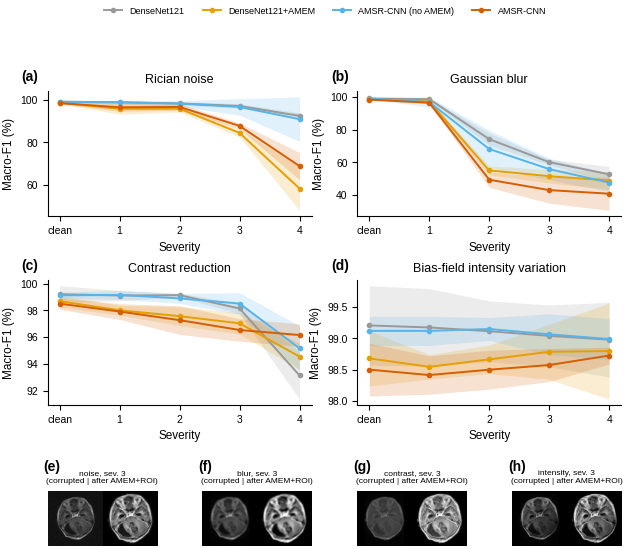

,Clean F1 (%),"noise F1 (%, mean sev.1-4)","blur F1 (%, mean sev.1-4)","contrast F1 (%, mean sev.1-4)","intensity F1 (%, mean sev.1-4)",Retention (%) mean+-SD,Worst-case F1 (%)
Model,,,,,,,
DenseNet121,99.205997,96.747406,71.409124,97.384202,99.075998,91.9 +- 0.5,52.590705
DenseNet121+AMEM,98.679603,83.617145,63.152598,96.793103,98.697686,86.7 +- 0.9,48.793186
AMSR-CNN (no AMEM),99.118723,96.198578,67.112126,97.930773,99.079955,90.9 +- 2.2,47.494402
AMSR-CNN,98.500359,87.479138,57.367335,96.971481,98.552972,86.4 +- 1.3,40.700927


In [27]:
# Figure 10: degradation curves (macro-F1) + example corrupted inputs;  Table 9: retention
ROB_COL = {BASE: "#999999", "DenseNet121+AMEM": "#E69F00", "AMSR-CNN (no AMEM)": "#56B4E9", FULL: "#D55E00"}
fig = plt.figure(figsize=(7.4, 6.2)); gs = GridSpec(3, 4, figure=fig, height_ratios=[1, 1, 0.8], hspace=0.55, wspace=0.42)
titles = dict(noise="Rician noise", blur="Gaussian blur", contrast="Contrast reduction", intensity="Bias-field intensity variation")
for i, kind in enumerate(PERT):
    ax = fig.add_subplot(gs[i // 2, (i % 2) * 2:(i % 2) * 2 + 2]); panel(ax, "abcd"[i], dx=-0.1)
    for n in ROB_MODELS:
        d = ROB[(ROB.model == n) & ((ROB.kind == kind) | (ROB.kind == "clean"))]
        g = d.groupby("level").f1.agg(["mean", "std"]).fillna(0)
        ax.plot(g.index, g["mean"] * 100, "o-", ms=3, color=ROB_COL[n], label=n); ax.fill_between(g.index, (g["mean"] - g["std"]) * 100, (g["mean"] + g["std"]) * 100, color=ROB_COL[n], alpha=0.18, lw=0)
    ax.set_xticks([0, 1, 2, 3, 4]); ax.set_xticklabels(["clean", "1", "2", "3", "4"]); ax.set_xlabel("Severity"); ax.set_ylabel("Macro-F1 (%)"); ax.set_title(titles[kind])
    if i == 0: leg_h = ax.get_legend_handles_labels()
fig.legend(*leg_h, loc="upper center", ncol=4, bbox_to_anchor=(0.5, 1.03), fontsize=6.5)
for j, (kind, lv) in enumerate([("noise", 3), ("blur", 3), ("contrast", 3), ("intensity", 3)]):
    ax = fig.add_subplot(gs[2, j]); raw_im, am_im = EX_PERT[(kind, lv)]
    ax.imshow(np.hstack([cv2.resize(raw_im, (IMG, IMG)), am_im]), cmap="gray", vmin=0, vmax=255); ax.axis("off")
    ax.set_title(f"{kind}, sev. {lv}\n(corrupted | after AMEM+ROI)", fontsize=6); panel(ax, "efgh"[j], dx=-0.04, dy=1.32)
save_fig(fig, "Fig10_robustness_degradation")

clean = ROB[ROB.kind == "clean"].groupby("model").f1.mean()
rows = []
for n in ROB_MODELS:
    r = {"Model": n, "Clean F1 (%)": 100 * clean[n]}
    for kind in PERT:
        r[f"{kind} F1 (%, mean sev.1-4)"] = 100 * ROB[(ROB.model == n) & (ROB.kind == kind)].f1.mean()
    perseed = ROB[(ROB.model == n) & (ROB.kind != "clean")].groupby("seed").f1.mean() / ROB[(ROB.model == n) & (ROB.kind == "clean")].groupby("seed").f1.mean()
    r["Retention (%) mean+-SD"] = f"{100*perseed.mean():.1f} +- {100*perseed.std(ddof=0):.1f}"; r["_ret"] = float(perseed.mean())
    r["Worst-case F1 (%)"] = 100 * ROB[(ROB.model == n) & (ROB.kind != "clean")].groupby(["kind", "level"]).f1.mean().min()
    rows.append(r)
T9 = pd.DataFrame(rows).set_index("Model"); RET = T9.pop("_ret"); save_table(T9, "T9_robustness_summary", float_fmt="%.2f"); display(T9)

## 11. External validation (independent MRI dataset, zero-shot cross-domain)
No external image is used for training, early stopping, calibration or any hyper-parameter. We report (i) performance, (ii) calibration shift, (iii) the effect of removing near-duplicates shared with BRISC, and (iv) the learned-feature domain gap (t-SNE of the penultimate representation).

In [28]:
if not HAS_EXT:
    print("External dataset not found: §11 skipped. Attach one in Kaggle (Add Input) or set EXTERNAL_ROOT_OVERRIDE and re-run from §1.")
else:
    y_ext = Y["ext"]; keep = ~df_ext.dup_with_brisc.values
    rows = []
    for name in RUN_VARIANTS:
        per = pd.DataFrame([metrics_from_probs(y_ext, get_P(name, "ext", s)) for s in CFG["seeds"]])
        Pe = get_P(name, "ext"); me = metrics_from_probs(y_ext, Pe); ci = boot_ci(y_ext, Pe, keys=("accuracy", "macro_f1", "auc"))
        mk = metrics_from_probs(y_ext[keep], Pe[keep]) if keep.sum() > 50 and len(np.unique(y_ext[keep])) == N_CLS else {"accuracy": np.nan, "macro_f1": np.nan}
        rows.append({"Variant": name, "Acc (%) mean+-SD": f"{100*per.accuracy.mean():.2f} +- {100*per.accuracy.std(ddof=0):.2f}",
                     "Macro-F1 (%) mean+-SD": f"{100*per.macro_f1.mean():.2f} +- {100*per.macro_f1.std(ddof=0):.2f}",
                     "Ensemble Acc (%) [95% CI]": fmt_ci(me["accuracy"], ci["accuracy"]), "Ensemble Macro-F1 (%) [95% CI]": fmt_ci(me["macro_f1"], ci["macro_f1"]),
                     "Ensemble AUC": round(me["auc"], 4), "ECE (ens.)": round(ece_mce(Pe, y_ext)[0], 4),
                     "Acc (%) w/o BRISC near-dups": round(100 * mk["accuracy"], 2) if not np.isnan(mk["accuracy"]) else np.nan,
                     "Drop vs BRISC test F1 (pp)": round(100 * (metrics_from_probs(y_te, get_P(name, "test"))["macro_f1"] - me["macro_f1"]), 2)})
    T10 = pd.DataFrame(rows).set_index("Variant"); save_table(T10, "T10_external_validation"); display(T10.T)

    P_e = get_P(FULL, "ext"); pred_e = P_e.argmax(1); cm_e = confusion_matrix(y_ext, pred_e, labels=range(N_CLS))
    # embeddings of the first seed's final model for the domain-gap plot
    rng = np.random.default_rng(3); nt = CFG["tsne_n"]
    ib = rng.choice(len(te_i), min(nt, len(te_i)), replace=False); ie = rng.choice(len(y_ext), min(nt, len(y_ext)), replace=False)
    Eb = embeddings(xmodel, Xam_b[te_i][ib]).numpy(); Ee = embeddings(xmodel, Xam_e[ie]).numpy()
    Z = TSNE(n_components=2, perplexity=min(30, (len(Eb) + len(Ee)) // 4), init="pca", random_state=0).fit_transform(np.vstack([Eb, Ee]))
    Zb, Ze = Z[:len(Eb)], Z[len(Eb):]

    fig, axes = plt.subplots(2, 3, figsize=(7.4, 4.9)); axes = axes.ravel()
    sns.heatmap(cm_e, annot=True, fmt="d", cmap="Oranges", cbar=False, ax=axes[0], annot_kws={"size": 7}, linewidths=0.5, linecolor="white",
                xticklabels=[CLS_PRETTY[c] for c in CLASSES], yticklabels=[CLS_PRETTY[c] for c in CLASSES])
    axes[0].set_title("External confusion matrix"); axes[0].set_xlabel("Predicted"); axes[0].set_ylabel("True"); axes[0].tick_params(axis="x", rotation=30); panel(axes[0], "a", dx=-0.25)
    Y1e = label_binarize(y_ext, classes=range(N_CLS))
    for c in range(N_CLS):
        fp, tp, _ = roc_curve(Y1e[:, c], P_e[:, c]); axes[1].plot(fp, tp, color=CLS_COL[CLASSES[c]], label=f"{CLS_PRETTY[CLASSES[c]]} ({roc_auc_score(Y1e[:, c], P_e[:, c]):.3f})")
    axes[1].plot([0, 1], [0, 1], "k:", lw=0.7); axes[1].set_xlabel("FPR"); axes[1].set_ylabel("TPR"); axes[1].set_title("External ROC"); axes[1].legend(fontsize=6); panel(axes[1], "b")
    names_ = [n for n in RUN_VARIANTS]; f1b = [metrics_from_probs(y_te, get_P(n, "test"))["macro_f1"] * 100 for n in names_]; f1e = [metrics_from_probs(y_ext, get_P(n, "ext"))["macro_f1"] * 100 for n in names_]
    xx = np.arange(len(names_)); axes[2].bar(xx - 0.18, f1b, 0.36, color="#0072B2", label="BRISC test"); axes[2].bar(xx + 0.18, f1e, 0.36, color="#D55E00", label="External")
    axes[2].set_xticks(xx); axes[2].set_xticklabels([n.replace("AMSR-CNN", "AMSR").replace("DenseNet121", "DN121") for n in names_], rotation=60, ha="right", fontsize=6)
    axes[2].set_ylabel("Macro-F1 (%)"); axes[2].legend(fontsize=6); axes[2].set_title("Cross-domain generalisation"); panel(axes[2], "c", dx=-0.2)
    axes[3].scatter(*Zb.T, s=5, c="#0072B2", alpha=0.6, label="BRISC test"); axes[3].scatter(*Ze.T, s=5, c="#D55E00", alpha=0.6, label="External")
    axes[3].set_title("t-SNE: dataset (domain gap)"); axes[3].legend(fontsize=6, markerscale=2); axes[3].set_xticks([]); axes[3].set_yticks([]); panel(axes[3], "d")
    for c in range(N_CLS):
        axes[4].scatter(*Zb[y_te[ib] == c].T, s=5, color=CLS_COL[CLASSES[c]], alpha=0.7, marker="o"); axes[4].scatter(*Ze[y_ext[ie] == c].T, s=7, color=CLS_COL[CLASSES[c]], alpha=0.7, marker="^", label=CLS_PRETTY[CLASSES[c]])
    axes[4].set_title("t-SNE: class (o BRISC, ^ external)"); axes[4].legend(fontsize=6, markerscale=1.5); axes[4].set_xticks([]); axes[4].set_yticks([]); panel(axes[4], "e")
    e1, _, rr1 = ece_mce(P_e, y_ext); e0, _, rr0 = ece_mce(get_P(FULL, "test"), y_te)
    axes[5].plot(rr0[:, 0], rr0[:, 1], "o-", ms=3, color="#0072B2", label=f"BRISC (ECE {e0:.3f})"); axes[5].plot(rr1[:, 0], rr1[:, 1], "o-", ms=3, color="#D55E00", label=f"External (ECE {e1:.3f})")
    axes[5].plot([0, 1], [0, 1], "k:", lw=0.7); axes[5].set_xlabel("Confidence"); axes[5].set_ylabel("Accuracy"); axes[5].set_title("Calibration under domain shift"); axes[5].legend(fontsize=6); panel(axes[5], "f")
    plt.tight_layout(); save_fig(fig, "Fig11_external_validation")

External dataset not found: §11 skipped. Attach one in Kaggle (Add Input) or set EXTERNAL_ROOT_OVERRIDE and re-run from §1.


## 12. Statistical validation
* **Ablation study** (Table 11): each rung versus the full model.
* **Significance tests** on the BRISC test set: exact **McNemar** test on seed-ensemble predictions and on every seed-matched pair, **Holm-adjusted**; **paired bootstrap** CI of the macro-F1 difference.
* **Error analysis**: confusions, error rate by plane and by image-quality tertile (Wilson 95 % CI), and a gallery of misclassified slices.

With only a few seeds, between-seed tests have little power: the ensemble-level McNemar and paired-bootstrap results are the primary evidence, and seed-level results show consistency.

,"Delta macro-F1 (pp, seed mean)",Delta macro-F1 ensemble (pp) [95% CI],Full right / other wrong,Full wrong / other right,McNemar p (ensemble),McNemar p seed-wise (median),Holm-adj. p (ensemble),Significant (alpha=.05)
Compared with,,,,,,,,
DenseNet121,-0.705638,"-0.78 [-1.38, -0.26]",1,10,0.011719,0.109375,0.058594,no
DenseNet121+AMEM,-0.179243,"-0.07 [-0.52, +0.38]",3,4,1.000000,0.607239,1.000000,no
MS-fixed,-0.183807,"-0.25 [-0.69, +0.18]",2,5,0.453125,0.423950,1.000000,no
MS-fixed+Attn,-0.244690,"-0.06 [-0.58, +0.45]",4,5,1.000000,0.647606,1.000000,no
AMSR-CNN (no AMEM),-0.618364,"-0.33 [-1.02, +0.36]",6,10,0.454498,0.041389,1.000000,no


,AMEM+ROI,Multi-scale,Attention,Adaptive fusion,Acc (%),Macro-F1 (%),AUC,Ext. F1 (%),ECE (T-scaled)
Variant,,,,,,,,,
DenseNet121,no,no,no,no,99.10 +- 0.57,99.21 +- 0.52,0.9995,n/a,0.0068
DenseNet121+AMEM,yes,no,no,no,98.50 +- 0.41,98.68 +- 0.36,0.9993,n/a,0.0091
MS-fixed,yes,yes,no,no,98.53 +- 0.12,98.68 +- 0.09,0.9992,n/a,0.0074
MS-fixed+Attn,yes,yes,yes,no,98.60 +- 0.14,98.75 +- 0.14,0.9995,n/a,0.0074
AMSR-CNN,yes,yes,yes,yes,98.30 +- 0.37,98.50 +- 0.34,0.9990,n/a,0.0073
AMSR-CNN (no AMEM),no,yes,yes,yes,99.03 +- 0.17,99.12 +- 0.19,0.9993,n/a,0.0060


[fig] Fig12_ablation_study.png  2618x890px  dpi=(360, 360)


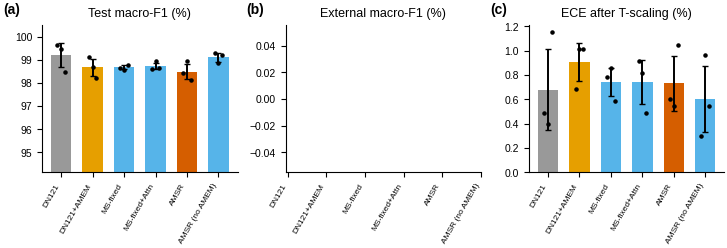

In [29]:
def mcnemar_p(y, pa, pb):
    a, b = (pa == y), (pb == y); n01, n10 = int((~a & b).sum()), int((a & ~b).sum())
    return mcnemar([[int((a & b).sum()), n10], [n01, int((~a & ~b).sum())]], exact=True).pvalue, n10, n01   # n10: A right, B wrong

def paired_boot_delta(y, Pa, Pb, n=None, seed=0):
    n = n or CFG["n_boot"]; rng = np.random.default_rng(seed); N = len(y); pa, pb = Pa.argmax(1), Pb.argmax(1)
    d = [macro_f1(y[i], pa[i]) - macro_f1(y[i], pb[i]) for i in (rng.integers(0, N, N) for _ in range(n))]
    return macro_f1(y, pa) - macro_f1(y, pb), np.percentile(d, [2.5, 97.5])

others = [n for n in RUN_VARIANTS if n != FULL]
P_f = get_P(FULL, "test"); rows = []
for n in others:
    P_o = get_P(n, "test"); p_ens, n10, n01 = mcnemar_p(y_te, P_f.argmax(1), P_o.argmax(1)); d, ci = paired_boot_delta(y_te, P_f, P_o)
    seed_p = [mcnemar_p(y_te, get_P(FULL, "test", s).argmax(1), get_P(n, "test", s).argmax(1))[0] for s in CFG["seeds"]]
    f1_f = [metrics_from_probs(y_te, get_P(FULL, "test", s), full=False)["macro_f1"] for s in CFG["seeds"]]
    f1_o = [metrics_from_probs(y_te, get_P(n, "test", s), full=False)["macro_f1"] for s in CFG["seeds"]]
    rows.append({"Compared with": n, "Delta macro-F1 (pp, seed mean)": 100 * (np.mean(f1_f) - np.mean(f1_o)), "Delta macro-F1 ensemble (pp) [95% CI]": f"{100*d:+.2f} [{100*ci[0]:+.2f}, {100*ci[1]:+.2f}]",
                 "Full right / other wrong": n10, "Full wrong / other right": n01, "McNemar p (ensemble)": p_ens, "McNemar p seed-wise (median)": float(np.median(seed_p))})
T11 = pd.DataFrame(rows).set_index("Compared with")
if len(T11):
    T11["Holm-adj. p (ensemble)"] = multipletests(T11["McNemar p (ensemble)"].values, method="holm")[1]
    T11["Significant (alpha=.05)"] = np.where(T11["Holm-adj. p (ensemble)"] < 0.05, "yes", "no")
save_table(T11, "T11_significance_vs_full_model", float_fmt="%.4g"); display(T11)

# ablation table (single table for the manuscript)
abl = []
for n in RUN_VARIANTS:
    ps = pd.DataFrame([metrics_from_probs(y_te, get_P(n, "test", s)) for s in CFG["seeds"]])
    v = VARIANTS[n]; abl.append({"Variant": n, "AMEM+ROI": "yes" if v["input"] == "amem" else "no", "Multi-scale": "yes" if (not v["plain"] and v["multiscale"]) else "no",
                                 "Attention": "yes" if (not v["plain"] and v["attention"]) else "no", "Adaptive fusion": "yes" if (not v["plain"] and v["fusion"] == "adaptive") else "no",
                                 "Acc (%)": f"{100*ps.accuracy.mean():.2f} +- {100*ps.accuracy.std(ddof=0):.2f}", "Macro-F1 (%)": f"{100*ps.macro_f1.mean():.2f} +- {100*ps.macro_f1.std(ddof=0):.2f}",
                                 "AUC": f"{ps.auc.mean():.4f}", "Ext. F1 (%)": (f"{100*np.mean([metrics_from_probs(Y['ext'], get_P(n, 'ext', s), full=False)['macro_f1'] for s in CFG['seeds']]):.2f}" if HAS_EXT else "n/a"),
                                 "ECE (T-scaled)": f"{np.mean([ece_mce(get_P(n, 'test', s, calibrated=True), y_te)[0] for s in CFG['seeds']]):.4f}"})
T12 = pd.DataFrame(abl).set_index("Variant"); save_table(T12, "T12_ablation_study"); display(T12)

fig, axes = plt.subplots(1, 3, figsize=(7.4, 2.7)); xs_ = np.arange(len(RUN_VARIANTS)); lab = [n.replace("AMSR-CNN", "AMSR").replace("DenseNet121", "DN121") for n in RUN_VARIANTS]
for ax, (ttl, fn), L in zip(axes, [("Test macro-F1 (%)", lambda n, s: metrics_from_probs(y_te, get_P(n, "test", s), full=False)["macro_f1"] * 100),
                                   ("External macro-F1 (%)", lambda n, s: metrics_from_probs(Y["ext"], get_P(n, "ext", s), full=False)["macro_f1"] * 100 if HAS_EXT else np.nan),
                                   ("ECE after T-scaling (%)", lambda n, s: ece_mce(get_P(n, "test", s, calibrated=True), y_te)[0] * 100)], "abc"):
    vals = np.array([[fn(n, s) for s in CFG["seeds"]] for n in RUN_VARIANTS])
    ax.bar(xs_, np.nanmean(vals, 1), yerr=np.nanstd(vals, 1), capsize=2.5, color=[ROB_COL.get(n, "#56B4E9") if n != FULL else "#D55E00" for n in RUN_VARIANTS], width=0.65)
    for j in range(vals.shape[1]): ax.scatter(xs_ + (j - (vals.shape[1] - 1) / 2) * 0.12, vals[:, j], s=5, color="k", zorder=3)
    ax.set_xticks(xs_); ax.set_xticklabels(lab, rotation=60, ha="right", fontsize=6); ax.set_title(ttl); panel(ax, L, dx=-0.2)
    if "F1" in ttl and not np.all(np.isnan(vals)): ax.set_ylim(max(0, np.nanmin(vals) - 4), min(100.5, np.nanmax(vals) + 1.5))
plt.tight_layout(); save_fig(fig, "Fig12_ablation_study")

Total errors: 13 of 1000 (error rate 1.30%)


,count
Glioma -> Meningioma,5
Meningioma -> Pituitary,5
Glioma -> Pituitary,1
Meningioma -> Glioma,1
Pituitary -> Meningioma,1


[fig] Fig13_error_analysis.png  2590x784px  dpi=(360, 360)


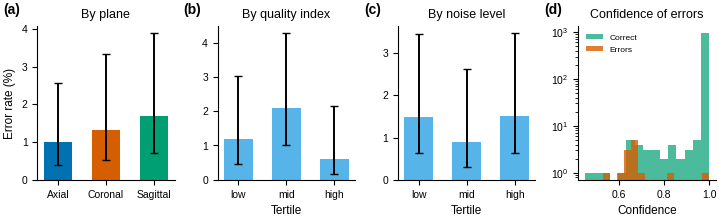

[fig] Fig14_misclassified_gallery.png  3094x879px  dpi=(360, 360)


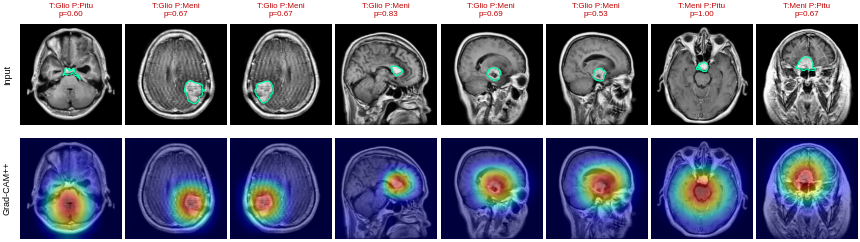

,stem,cls,pred,plane,confidence
4,brisc2025_test_00005_gl_ax_t1,glioma,pituitary,ax,0.603728
19,brisc2025_test_00020_gl_ax_t1,glioma,meningioma,ax,0.671341
63,brisc2025_test_00064_gl_ax_t1,glioma,meningioma,ax,0.666768
228,brisc2025_test_00229_gl_sa_t1,glioma,meningioma,sa,0.834295
232,brisc2025_test_00233_gl_sa_t1,glioma,meningioma,sa,0.690293
233,brisc2025_test_00234_gl_sa_t1,glioma,meningioma,sa,0.525967
364,brisc2025_test_00365_me_ax_t1,meningioma,pituitary,ax,1.000000
402,brisc2025_test_00403_me_co_t1,meningioma,pituitary,co,0.669519
417,brisc2025_test_00418_me_co_t1,meningioma,pituitary,co,0.672975
425,brisc2025_test_00426_me_co_t1,meningioma,pituitary,co,0.646488


In [30]:
# ---- Error analysis
pred_f = P_f.argmax(1); err = pred_f != y_te; QI_te = Q_brisc.QI.values[te_i]
meta = pd.DataFrame({"y": y_te, "pred": pred_f, "err": err, "plane": df_brisc.plane.values[te_i], "conf": P_f.max(1),
                     "sharp": Q_brisc.sharpness.values[te_i], "noise": Q_brisc.noise.values[te_i], "contrast": Q_brisc.contrast.values[te_i], "QI": QI_te})
for k in ["sharp", "noise", "contrast", "QI"]:
    meta[k + "_t"] = pd.qcut(meta[k], 3, labels=["low", "mid", "high"], duplicates="drop") if meta[k].nunique() > 3 else "all"

def wilson(k, n, z=1.96):
    if n == 0: return np.nan, np.nan, np.nan
    p = k / n; d = 1 + z * z / n; c = (p + z * z / (2 * n)) / d; h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d; return p, c - h, c + h

pair = pd.Series([f"{CLS_PRETTY[CLASSES[a]]} -> {CLS_PRETTY[CLASSES[b]]}" for a, b in zip(y_te[err], pred_f[err])]).value_counts().rename("count")
print("Total errors:", int(err.sum()), "of", len(err), f"(error rate {100*err.mean():.2f}%)"); display(pair.to_frame())
save_table(pair.to_frame(), "T13_error_confusion_pairs")

fig, axes = plt.subplots(1, 4, figsize=(7.4, 2.4))
ax = axes[0]; panel(ax, "a", dx=-0.25)
for i, p_ in enumerate([p for p in PLANES if p in set(meta.plane)]):
    k, n_ = int(meta[meta.plane == p_].err.sum()), int((meta.plane == p_).sum()); pe, lo, hi = wilson(k, n_)
    ax.bar(i, 100 * pe, yerr=[[100 * (pe - lo)], [100 * (hi - pe)]], color=OKABE[i], capsize=3, width=0.6)
ax.set_xticks(range(len(set(meta.plane)))); ax.set_xticklabels([{"ax": "Axial", "co": "Coronal", "sa": "Sagittal"}.get(p, p) for p in PLANES if p in set(meta.plane)]); ax.set_ylabel("Error rate (%)"); ax.set_title("By plane")
for ax, k, ttl, L in zip(axes[1:3], ["QI_t", "noise_t"], ["By quality index", "By noise level"], "bc"):
    panel(ax, L, dx=-0.25)
    for i, t in enumerate(["low", "mid", "high"]):
        sub = meta[meta[k] == t]
        if len(sub): pe, lo, hi = wilson(int(sub.err.sum()), len(sub)); ax.bar(i, 100 * pe, yerr=[[100 * (pe - lo)], [100 * (hi - pe)]], color="#56B4E9", capsize=3, width=0.6)
    ax.set_xticks(range(3)); ax.set_xticklabels(["low", "mid", "high"]); ax.set_xlabel("Tertile"); ax.set_title(ttl)
ax = axes[3]; panel(ax, "d", dx=-0.25); cc = ece_mce(P_f, y_te)[2]
ax.hist(meta.conf[~meta.err], bins=15, color="#009E73", alpha=0.7, label="Correct", log=True)
if meta.err.any(): ax.hist(meta.conf[meta.err], bins=15, color="#D55E00", alpha=0.8, label="Errors", log=True)
ax.set_xlabel("Confidence"); ax.set_title("Confidence of errors"); ax.legend(fontsize=6)
plt.tight_layout(); save_fig(fig, "Fig13_error_analysis")

if err.any():
    wi = np.where(err)[0][:8]; mq2, tq2, _ = explain_batch(wi)
    fig, axes = plt.subplots(2, len(wi), figsize=(1.35 * len(wi), 2.9)); axes = np.array(axes).reshape(2, -1)
    for j, i in enumerate(wi):
        axes[0, j].imshow(Xam_b[te_i][i], cmap="gray"); axes[1, j].imshow(overlay(Xam_b[te_i][i], mq2["Grad-CAM++"][j]))
        if GT_test[i].any(): axes[0, j].contour(GT_test[i], levels=[0.5], colors="#00FFAA", linewidths=0.8)
        axes[0, j].set_title(f"T:{CLS_PRETTY[CLASSES[y_te[i]]][:4]} P:{CLS_PRETTY[CLASSES[pred_f[i]]][:4]}\np={P_f[i].max():.2f}", fontsize=5.8, color="#C00000")
        for a in axes[:, j]: a.axis("off")
    axes[0, 0].text(-0.08, 0.5, "Input", transform=axes[0, 0].transAxes, rotation=90, ha="right", va="center", fontsize=6.5)
    axes[1, 0].text(-0.08, 0.5, "Grad-CAM++", transform=axes[1, 0].transAxes, rotation=90, ha="right", va="center", fontsize=6.5)
    plt.subplots_adjust(wspace=0.04, hspace=0.04); save_fig(fig, "Fig14_misclassified_gallery")
err_df = df_brisc.iloc[te_i][err].assign(pred=[CLASSES[i] for i in pred_f[err]], confidence=P_f.max(1)[err])[["stem", "cls", "pred", "plane", "confidence"]]
save_table(err_df, "T14_misclassified_slices", index=False)

## 13. Final AMSR-CNN summary and export
Four-axis summary of the claims in the framework (*accurate, robust, explainable, reliable*), plus efficiency. Each axis is a single, transparent number:
**Accurate** = test macro-F1; **Robust** = mean F1 retention under all 16 perturbations; **Explainable** = mean of localisation IoU-normalised score (pointing game) and insertion-minus-deletion AUC; **Reliable** = 1 - ECE after temperature scaling. These are descriptive summaries, not a replacement for the full tables.

[fig] Fig15_final_model_profile.png  1332x1140px  dpi=(360, 360)


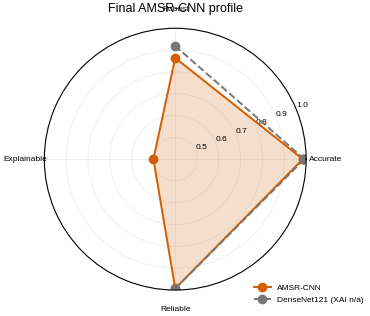

,Params (M),"Inference (ms/image, batch 32)"
Model,,
DenseNet121,6.96,3.17
AMSR-CNN,8.36,3.42


{
  "test_metrics_ensemble": {
    "accuracy": 0.987,
    "macro_f1": 0.9887263519837063,
    "balanced_acc": 0.9883591940713293,
    "precision": 0.9891759903645441,
    "recall": 0.9883591940713293,
    "mcc": 0.9822744802602016,
    "kappa": 0.9822408738582931,
    "auc": 0.9996627844028713
  },
  "bootstrap_ci_95": {
    "accuracy": [
      0.98,
      0.993
    ],
    "macro_f1": [
      0.9822131328442173,
      0.9940356572785856
    ],
    "mcc": [
      0.972509825045912,
      0.9905004517076011
    ],
    "auc": [
      0.9990691026630829,
      0.9999681744933636
    ]
  },
  "profile": {
    "Accurate": 0.9850035938377536,
    "Robust": 0.8639263413674471,
    "Explainable": 0.5001453868569837,
    "Reliable": 0.9926797050436338
  },
  "learned_scale_weights": [
    0.2831632196903229,
    0.27634426951408386,
    0.44049254059791565
  ]
}

All figures (PNG @360 DPI + PDF) -> /kaggle/working/amsr_cnn_outputs/figures
All tables (CSV + LaTeX) -> /kaggle/working/amsr_cnn_outp

In [31]:
acc_axis = np.mean([metrics_from_probs(y_te, get_P(FULL, "test", s), full=False)["macro_f1"] for s in CFG["seeds"]])
rob_axis = float(RET[FULL]) if FULL in RET.index else np.nan
xa = XQ["Grad-CAM++"]; exp_axis = float(np.clip(0.5 * xa.pointing.mean() + 0.5 * (xa.insertion.mean() - xa.deletion.mean()), 0, 1))
rel_axis = 1 - np.mean([ece_mce(get_P(FULL, "test", s, calibrated=True), y_te)[0] for s in CFG["seeds"]])
axes_v = dict(Accurate=acc_axis, Robust=rob_axis, Explainable=exp_axis, Reliable=rel_axis)
base_v = dict(Accurate=np.mean([metrics_from_probs(y_te, get_P(BASE, "test", s), full=False)["macro_f1"] for s in CFG["seeds"]]),
              Robust=float(RET[BASE]) if BASE in RET.index else np.nan, Explainable=np.nan,
              Reliable=1 - np.mean([ece_mce(get_P(BASE, "test", s, calibrated=True), y_te)[0] for s in CFG["seeds"]]))
ang = np.linspace(0, 2 * np.pi, 5); fig = plt.figure(figsize=(3.6, 3.4)); ax = fig.add_subplot(111, polar=True)
vv = list(axes_v.values()) + [list(axes_v.values())[0]]; ax.plot(ang, vv, "o-", color="#D55E00", label="AMSR-CNN"); ax.fill(ang, vv, color="#D55E00", alpha=0.2)
bv = [0 if np.isnan(x) else x for x in list(base_v.values())]; bv += [bv[0]]; ax.plot(ang, bv, "o--", color="#777777", label="DenseNet121 (XAI n/a)")
ax.set_xticks(ang[:-1]); ax.set_xticklabels(list(axes_v)); lo_ = max(0.0, min([x for x in vv + bv if x > 0]) - 0.1); ax.set_ylim(lo_, 1.0); ax.tick_params(labelsize=6)
ax.legend(loc="lower right", bbox_to_anchor=(1.25, -0.08), fontsize=6); ax.set_title("Final AMSR-CNN profile", fontsize=9, pad=12)
save_fig(fig, "Fig15_final_model_profile")

# efficiency
xb_ = torch.rand(32, 1, IMG, IMG, device=DEVICE); eff = []
for n in [BASE, FULL]:
    m_ = make_model(n, pretrained=False).to(DEVICE).eval()
    with torch.no_grad():
        for _ in range(2): m_(xb_)
        if DEVICE.type == "cuda": torch.cuda.synchronize()
        t0 = time.time()
        for _ in range(5): m_(xb_)
        if DEVICE.type == "cuda": torch.cuda.synchronize()
    eff.append({"Model": n, "Params (M)": round(n_par[n], 2), "Inference (ms/image, batch 32)": round((time.time() - t0) / (5 * 32) * 1000, 2)})
save_table(pd.DataFrame(eff).set_index("Model"), "T15_efficiency"); display(pd.DataFrame(eff).set_index("Model"))

# ----- export everything
final = dict(config=CFG, env=env_info, pretrained_imagenet_loaded=PRETRAINED_OK, quick_run=QUICK_RUN, classes=CLASSES,
             test_metrics_ensemble={k: float(v) for k, v in metrics_from_probs(y_te, P_f).items()}, bootstrap_ci_95={k: list(v) for k, v in MAIN_CI[FULL].items()},
             profile=axes_v, learned_scale_weights=[float(x) for x in np.mean([RES[(FULL, s)]["alpha"] for s in CFG["seeds"]], 0)],
             leakage_audit=audit)
json.dump(final, open(OUT_DIR / "tables" / "final_summary.json", "w"), indent=2, default=str)
np.save(OUT_DIR / "tables" / "test_probs_AMSR_CNN_ensemble.npy", P_f)
shutil.make_archive(str(OUT_DIR.parent / "amsr_cnn_figures_tables"), "zip", OUT_DIR, "figures")
print(json.dumps({k: final[k] for k in ["test_metrics_ensemble", "bootstrap_ci_95", "profile", "learned_scale_weights"]}, indent=2))
print("\nAll figures (PNG @360 DPI + PDF) ->", OUT_DIR / "figures"); print("All tables (CSV + LaTeX) ->", OUT_DIR / "tables")
if QUICK_RUN: print("\n*** QUICK_RUN: these numbers only verify that the code runs. Re-run with QUICK_RUN off. ***")

### Reporting checklist for the manuscript
1. Describe the split honestly: BRISC provides an official train/test split; validation was carved from train (stratified by class and plane). Report the leakage audit table and state that patient IDs are unavailable.
2. Report seed-wise mean +- SD **and** the bootstrap CIs; give the exact test (McNemar, Holm) used for every "significant" claim.
3. State that the external dataset was never used for training, early stopping or calibration, and report results with and without near-duplicates.
4. Discuss that AMEM changes image statistics by design (Fig. 4) and that its value is judged by the ablation (Table 12) and robustness study (Table 9), not by quality metrics.
5. Explainability: report localisation/faithfulness numbers (Table 6) rather than only qualitative overlays; note attribution methods describe model behaviour, not clinical causality.
6. Limitations: 2-D T1 slices only, slice-level labels, a single external dataset, no prospective/clinical validation.